# Лабораторна 3. Токенізація та трансформери

У цій лабораторній роботі ви пройдете шлях від механіки токенізації до практичного використання готових мовних моделей:

- алгоритми токенізації (BPE, WordPiece, Unigram) — натренуєте всі три на власному тексті;
- mini-GPT з нуля — повторите тренування трансформера на своєму датасеті;
- готові моделі для різних NLP-задач — класифікація, генерація, переклад, Q&A та інше через `pipeline()`;
- порівняння кількох моделей на одній задачі;
- творчий застосунок на основі готової моделі.

Демо-ноутбук лекції 4 (`ransformers_demo.ipynb`) — основа для секцій 2-3, звертайтесь до нього як до довідника. Розділи 1 і 4 спираються на офіційний [Hugging Face LLM Course](https://huggingface.co/learn/llm-course/en/chapter1/1) — читайте відповідні розділи курсу перед виконанням, посилання додані в кожній секції.

## Матеріали

- [3Blue1Brown — Transformers, the tech behind LLMs](https://www.youtube.com/watch?v=wjZofJX0v4M)
- [3Blue1Brown — Attention in transformers, step-by-step](https://www.youtube.com/watch?v=eMlx5fFNoYc)
- [3Blue1Brown — How might LLMs store facts](https://www.youtube.com/watch?v=9-Jl0dxWQs8)
- [Hugging Face LLM Course — Chapter 1: Transformer Models](https://huggingface.co/learn/llm-course/en/chapter1/1)
- [Hugging Face LLM Course — Chapter 2: Using Transformers](https://huggingface.co/learn/llm-course/en/chapter2/1)
- [Hugging Face LLM Course — Chapter 6: The Tokenizers library](https://huggingface.co/learn/llm-course/en/chapter6/1)

## 0. Опрацюйте демо-ноутбук лекції 4

Прогляньте пояснення і запустіть усі клітинки демо-ноутбука.

Після цього дайте відповідь на запитання нижче.

### 0.1. Теоретичні питання (якщо потрібно дописати якийсь код, то в блоці "Мої відповіді наведіть відповідний код")

1. У розділі 2.1 демо тренер BPE отримує список окремих віршів, а не один склеєний рядок. Що б змінилось (і що б зламалось), якби ми передали один суцільний рядок?
2. З який етапів складається токенізація, поясніть сутність кожного з етапів (див. [туторіал по токенізації](https://huggingface.co/learn/llm-course/en/chapter6/8))
2. Що таке `"<unk>", "<eos>"` в 2.1.?
3. Зменшіть `VOCAB_SIZE` (2.1) удвічі-втричі (наприклад з 16000 до 4000-6000) і перетренуйте BPE-токенізатор на тому самому корпусі. Порівняйте середню кількість токенів на вірш і частку `<unk>` до/після зміни. Поясніть, чому менший словник не підвищує `<unk>`, але впливає на довжину закодованих послідовностей (а отже — і на кількість кроків, які "бачить" модель за той самий `CONTEXT_LEN`).
4. У розділі 2.2 між віршами вставлено токен `<eos>`. Навіщо? Що конкретно піде не так під час тренування mini-GPT, якщо цей роздільник прибрати?
5. Який формат мають і що репрезентують елементи тензорів `train_data` & `val_data` у розділі 2.3?
6. Допишіть в 3.2. `assert` тест, який перевіряє відповідність частин випадкового батчу.
7. У 3.3 `causal_mask` — нижньотрикутна матриця одиниць. Чому саме нижньотрикутна, а не верхньотрикутна? Що б змінилося в поведінці моделі при генерації тексту, якби маски не було?
8. У 3.10 генерація бере чекпоінт із найкращим `val_loss`, а не останній. За яких умов ці два чекпоінти збігаються, а за яких — ні? Подивіться на свою криву навчання (3.9) і скажіть, який випадок у вас.
10. Зменшіть `EVAL_INTERVAL` у 5 разів (наприклад з 250 до 50) і повторно запустіть тренування. Чи стала крива навчання (3.9) помітно гладкішою/інформативнішою? Скільки додаткового часу це коштує (частіші виклики `estimate_loss()` на `EVAL_ITERS` батчах), і чи є сенс робити `EVAL_INTERVAL` ще меншим?
11. У 4.2 той самий промпт дає дуже різний текст при `temperature=0.2` і `temperature=1.4`. Поясніть математично, що робить `temperature` з логітами перед `softmax`, і чому при дуже високій температурі текст стає майже випадковим.
12. За що саме відповідає параметр `top_p`?
13. У 4.2 змініть налаштування `enable_thinking=False` на `True` запустіть повторно клітинку і прокоментуйте зміни у результаті виконання.

# 0.2. Мої відповіді:

###1. У розділі 2.1 демо тренер BPE отримує список окремих віршів, а не один склеєний рядок. Що б змінилось (і що б зламалось), якби ми передали один суцільний рядок?
Якщо об’єднати всі вірші в один рядок, алгоритм BPE навчатиметься на спільному тексті без чіткого розмежування між ними. Через це можуть формуватися токени, які поєднують фрагменти сусідніх віршів. Помилки в роботі алгоритму не виникне, проте отриманий словник може відрізнятися від очікуваного. Тому важливо зберігати межі між окремими текстами..

###2. З який етапів складається токенізація, поясніть сутність кожного з етапів (див. [туторіал по токенізації](https://huggingface.co/learn/llm-course/en/chapter6/8))

Токенізація включає чотири послідовні етапи:
1. Нормалізація (Normalization) — приведення тексту до потрібного вигляду, наприклад уніфікація регістру або обробка пробілів.
2. Попереднє розбиття (Pre-tokenization) — поділ тексту на початкові фрагменти за визначеними правилами, тобто поділ на вірші, статті, окремі цілі сутності.
3. Робота моделі токенізації (Model) — перетворення отриманих фрагментів на токени відповідно до алгоритму та присвоєння їм числових ідентифікаторів.
4. Постобробка (Post-processing) — завершальна обробка результату, наприклад додавання спеціальних токенів початку або кінця послідовності.

###3. Що таке `"<unk>", "<eos>"` в 2.1.?

unk (unknown) — спеціальний токен, який використовується для позначення невідомого елемента тексту, якщо токенізатор не може його розпізнати або представити.

eos (end of sequence) — маркер, що вказує на завершення текстової послідовності.

###4. Зменшіть `VOCAB_SIZE` (2.1) удвічі-втричі (наприклад з 16000 до 4000-6000)...

Після скорочення словника з 16 000 до 6 000 токенів загальна кількість токенів у корпусі збільшилася з 18 421 968 до 21 041 508. При цьому частка unk в обох випадках залишилася нульовою.

Це пояснюється тим, що менший словник містить менше складених токенів, тому текст частіше розбивається на коротші частини. У результаті для представлення того самого тексту потрібно більше токенів, а за незмінної довжини контексту модель отримує менший обсяг тексту для аналізу.

###5. У розділі 2.2 між віршами вставлено токен `<eos>`. Навіщо? Що конкретно піде не так під час тренування mini-GPT, якщо цей роздільник прибрати?

Токен eos потрібен для явного позначення завершення кожного вірша. Він допомагає моделі розрізняти незалежні текстові послідовності.

Якщо прибрати цей роздільник, модель сприйматиме кінець одного вірша та початок наступного як безперервний текст. Через це вона може засвоювати штучні переходи між різними віршами, що негативно впливатиме на якість генерації.


###6. Який формат мають і що репрезентують елементи тензорів `train_data` & `val_data` у розділі 2.3?

train_data і val_data — це одновимірні тензори PyTorch із типом даних int64. Вони містять числові індекси токенів, на які було перетворено навчальний і перевірочний тексти.

Кожен індекс відповідає певному елементу словника BPE. Під час навчання модель використовує ці послідовності, щоб навчитися прогнозувати наступний токен за попередніми

###7. Допишіть в 3.2. `assert` тест, який перевіряє відповідність частин випадкового батчу.
Тест assert перевіряє, чи правильно сформовано навчальні пари: послідовність y має відповідати послідовності x, зміщеній на одну позицію. Якщо умова виконується, помилки не буде, а якщо ні — з’явиться повідомлення про невідповідність.

`Форма батчу x: torch.Size([64, 64])  y: torch.Size([64, 64])`

###8. У 3.3 `causal_mask` — нижньотрикутна матриця одиниць. Чому саме нижньотрикутна, а не верхньотрикутна? Що б змінилося в поведінці моделі при генерації тексту, якби маски не було?
Нижньотрикутна маска дозволяє кожній позиції враховувати поточний і попередні токени, блокуючи доступ до майбутніх. Це необхідно для авторегресивної генерації, коли наступний токен прогнозується лише на основі вже наявного тексту.

Якщо маску прибрати, під час навчання модель зможе використовувати інформацію з майбутніх позицій. Такий витік даних призведе до некоректного навчання та може погіршити якість генерації.


###9. У 3.10 генерація бере чекпоінт із найкращим `val_loss`, а не останній. За яких умов ці два чекпоінти збігаються, а за яких — ні? Подивіться на свою криву навчання (3.9) і скажіть, який випадок у вас.

Найкращий і останній чекпоінти збігаються, якщо найменше значення val_loss досягнуто саме наприкінці навчання. Якщо ж помилка на валідаційних даних раніше була меншою, найкращим вважатиметься чекпоінт із тієї попередньої ітерації.

У моєму випадку val_loss поступово знижувався та досягнув мінімального значення 5.040 на ітерації 7999. Отже, найкращий чекпоінт відповідає останньому збереженому стану моделі, хоча графіки train_loss і val_loss дещо відрізняються.

###10. Зменшіть `EVAL_INTERVAL` у 5 разів (наприклад з 250 до 50) і повторно запустіть тренування. Чи стала крива навчання (3.9) помітно гладкішою/інформативнішою? Скільки додаткового часу це коштує (частіші виклики `estimate_loss()` на `EVAL_ITERS` батчах), і чи є сенс робити `EVAL_INTERVAL` ще меншим?

Після зміни EVAL_INTERVAL із 250 на 50 модель почала оцінюватися частіше. Графік став детальнішим, проте не плавнішим, оскільки на ньому частіше відображаються короткочасні коливання значень помилки.

Тривалість запуску майже не змінилася: 6,5 хвилини замість 6,8 хвилини. Отже, у цьому експерименті частіше оцінювання було виправданим. Проте надмірне зменшення інтервалу може створити зайві обчислювальні витрати без суттєвого покращення аналізу навчання.

###11. У 4.2 той самий промпт дає дуже різний текст при `temperature=0.2` і `temperature=1.4`. Поясніть математично, що робить `temperature` з логітами перед `softmax`, і чому при дуже високій температурі текст стає майже випадковим.
Параметр temperature змінює розподіл імовірностей наступних токенів шляхом ділення логітів на температуру перед застосуванням softmax.

За низької температури, наприклад 0.2, різниця між імовірностями посилюється, тому модель частіше вибирає найімовірніші токени. За вищої температури, наприклад 1.4, розподіл стає рівномірнішим і зростає ймовірність вибору менш очікуваних варіантів. Через це текст стає різноманітнішим, але може втрачати логічну послідовність. За дуже високої температури вибір наближається до випадкового.

###12. За що саме відповідає параметр `top_p`?
Параметр top_p обмежує набір токенів, доступних для вибору під час генерації. Модель залишає найімовірніші токени, доки їхня сумарна ймовірність не досягне заданого порога, а решту виключає з вибору.

Менше значення top_p зазвичай робить генерацію більш передбачуваною, тоді як більше значення дозволяє розглядати ширший набір можливих продовжень.

###13. У 4.2 змініть налаштування `enable_thinking=False` на `True` запустіть повторно клітинку і прокоментуйте зміни у результаті виконання.
Коли enable_thinking=False, модель генерує текст без окремого блоку міркувань. Після встановлення enable_thinking=True вона може спочатку сформувати проміжний блок think, а потім перейти до основного результату.

У цьому експерименті замість продовження історії модель видала англомовний текст із повтореннями та неточностями. Це демонструє, що ввімкнення режиму thinking змінює спосіб формування відповіді, але саме по собі не гарантує кращого результату.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


---
## 1. Свій датасет

Знайдіть **свій** українськомовний текстовий корпус, достатній за обсягом для mini-GPT — наприклад, на [Hugging Face Datasets](https://huggingface.co/datasets?language=language:uk) або на [Kaggle](https://www.kaggle.com/datasets?search=ukrainian). Жанр і епоха — на ваш вибір (новини, художня література, вікіпедія, форуми, судові рішення тощо), головне — одна мова (українська) і достатньо тексту, щоб токенізатор і модель побачили бодай прості закономірності.

⚠️ Якщо датасет великий (сотні МБ тексту і більше) — кодуйте корпус пачками, як у демо 2.2 (`encode_batch` + конвертація в `numpy.int32`), інакше отримаєте помилку нестачі пам'яті (out of memory, OOM).

⚠️ Якщо датасет доступний лише через `streaming=True` (наприклад, через розмір) — `load_dataset(..., streaming=True).take(N)` повертає `IterableDataset`, у якого **нема** `.to_pandas()` і `len()`. Спершу матеріалізуйте вибірку в список, а вже потім — у `DataFrame`:
```python
rows = list(streamed_ds)
poems_df = pd.DataFrame(rows)
```

In [2]:
!pip install "transformers[sentencepiece]==5.18.0"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 33.6 MB/s  0:00:00
  Attempting uninstall: transformers
    Found existing installation: transformers 5.20.2
    Uninstalling transformers-5.20.2:
      Successfully uninstalled transformers-5.20.2


In [3]:
import os

from google.colab import drive
drive.mount("/content/drive")
ARTIFACT_DIR = "/content/drive/MyDrive/ai_systems/Lab3"

os.makedirs(ARTIFACT_DIR, exist_ok=True)
RUNS_DIR = os.path.join(ARTIFACT_DIR, "runs")
os.makedirs(RUNS_DIR, exist_ok=True)
print("Артефакти зберігаються в:", ARTIFACT_DIR)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Артефакти зберігаються в: /content/drive/MyDrive/ai_systems/Lab3


In [4]:
import torch
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Використовуємо:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Використовуємо: cuda
GPU: Tesla T4


In [5]:
import requests
import pandas as pd
from datasets import load_dataset

# Отримуємо посилання на Parquet-файли
api_url = (
    "https://huggingface.co/api/datasets/"
    "nthngdy/oscar-small/parquet/"
    "unshuffled_deduplicated_uk/train"
)

response = requests.get(api_url)
response.raise_for_status()
parquet_urls = response.json()

print("Знайдено файлів:", len(parquet_urls))

# Завантажуємо Parquet-файли локально
local_files = []

for i, file_url in enumerate(parquet_urls):
    file_response = requests.get(file_url)
    file_response.raise_for_status()

    file_path = f"oscar_uk_{i}.parquet"

    with open(file_path, "wb") as f:
        f.write(file_response.content)

    local_files.append(file_path)
    print(f"Завантажено: {file_path}")

# Читаємо локальні файли через datasets
dataset = load_dataset(
    "parquet",
    data_files={"train": local_files},
    split="train"
)

print("Кількість записів:", len(dataset))
print("Колонки:", dataset.column_names)

# Отримуємо тексти без додаткової обробки
poems_df = pd.DataFrame({
    "context_poem": dataset["text"]
})

print("Кількість текстів:", len(poems_df))
print(
    "Загальна кількість символів:",
    poems_df["context_poem"].str.len().sum()
)

print("\nПриклад тексту:\n", poems_df["context_poem"].iloc[0])



Знайдено файлів: 1
Завантажено: oscar_uk_0.parquet


Generating train split: 0 examples [00:00, ? examples/s]

Кількість записів: 392621
Колонки: ['id', 'text']
Кількість текстів: 392621
Загальна кількість символів: 110360653

Приклад тексту:
 Про надання роз'яснення (щодо форми письмового зобов'язання громадян про зворотне ввезення/вивезення товарів), Державна митна служба України


#1.2. Збираємо суцільний корпус

In [6]:
# Формуємо єдиний текстовий корпус із завантажених записів
texts_list = poems_df["context_poem"].dropna().tolist()
corpus_text = "\n\n".join(texts_list)

# Перевіряємо обсяг зібраних даних
print(f"Загальна довжина корпусу: {len(corpus_text):,} символів")
print("\nПочаток корпусу (перші 400 символів):\n")
print(corpus_text[:400])


Загальна довжина корпусу: 111,145,893 символів

Початок корпусу (перші 400 символів):

Про надання роз'яснення (щодо форми письмового зобов'язання громадян про зворотне ввезення/вивезення товарів), Державна митна служба України

У зв'язку із запитами митних органів стосовно надання роз'яснення щодо форми письмового зобов'язання громадян про зворотне ввезення/вивезення товарів повідомляємо.

Переміщення громадянами товарів через митний кордон України, умовою якого є надання митному о


#1.3. Базова статистика корпусу

In [7]:
# Аналізуємо словниковий склад текстового корпусу
word_list = corpus_text.split()
unique_words = {word.lower() for word in word_list}

# Виводимо основні статистичні показники
print(f"Загальна кількість слів: {len(word_list):,}")
print(f"Кількість різних слів: {len(unique_words):,}")

# Переглядаємо фрагмент тексту для перевірки даних
print("\nПриклад тексту з корпусу:\n")
print(corpus_text[:400])

Загальна кількість слів: 15,106,187
Кількість різних слів: 1,236,819

Приклад тексту з корпусу:

Про надання роз'яснення (щодо форми письмового зобов'язання громадян про зворотне ввезення/вивезення товарів), Державна митна служба України

У зв'язку із запитами митних органів стосовно надання роз'яснення щодо форми письмового зобов'язання громадян про зворотне ввезення/вивезення товарів повідомляємо.

Переміщення громадянами товарів через митний кордон України, умовою якого є надання митному о


---
## 2. Токенізатори: BPE, WordPiece, Unigram

Демо тренує лише BPE. У цій секції ви натренуєте й порівняєте всі три основні алгоритми токенізації на **своєму** тексті.

Матеріал — офіційний [Hugging Face LLM Course, розділ 6](https://huggingface.co/learn/llm-course/en/chapter6/1). Пройдіть і повторіть на своїх даних:

1. **[6.2. Тренування нового токенізатора на основі старого](https://huggingface.co/learn/llm-course/en/chapter6/2)** — найпростіший шлях: `tokenizer.train_new_from_iterator(...)` на основі архітектури готового токенізатора (наприклад, `Qwen/Qwen2.5-0.5B-Instruct`). Зробіть це як розминку перед ручними варіантами нижче.
2. **[6.5. Алгоритм BPE](https://huggingface.co/learn/llm-course/en/chapter6/5)** — повторіть покрокову реалізацію з туторіалу на своєму тексті, повністю вручну або за допомогою бібліотеки `tokenizers`.
3. **[6.6. Алгоритм WordPiece](https://huggingface.co/learn/llm-course/en/chapter6/6)** — так само.
4. **[6.7. Алгоритм Unigram](https://huggingface.co/learn/llm-course/en/chapter6/7)** — так само.

### 1.1. Порівняння

Для однакового `vocab_size` (візьміть, наприклад, 500 — на невеликому зразку тексту більший словник не встигне показати різницю) порівняйте три токенізатори в невеликій таблиці: розмір словника, кількість токенів на вашому зразку, скільки токенів виходить на кількох обраних словах (частотне й рідкісне — як у лекції). Коротко письмово: який алгоритм дав найкоротші послідовності на вашому тексті і чи це узгоджується з тим, що каже туторіал про природу кожного алгоритму?

#2.0 Підготовка даних
Задаємо спільні параметри для всіх трьох алгоритмів.

In [8]:
from collections import Counter
from tokenizers import Tokenizer, models, trainers, pre_tokenizers, decoders

# Спільні налаштування для експериментів
VOCAB_SIZE = 4000
SPECIAL_TOKENS = ["<unk>", "<eos>"]

# Отримуємо тексти з української вибірки OSCAR
texts = poems_df["context_poem"].dropna().tolist()

# Формуємо однакову підвибірку для всіх алгоритмів
sample_texts = texts[:3000]

print("Кількість доступних текстів:", len(texts))
print("Розмір експериментальної вибірки:", len(sample_texts))
print(
    "Загальний обсяг вибірки:",
    f"{sum(len(text) for text in sample_texts):,}",
    "символів"
)


Кількість доступних текстів: 392621
Розмір експериментальної вибірки: 3000
Загальний обсяг вибірки: 821,614 символів


#2.1. Розминка: тренування на основі готового токенізатора

In [9]:
# Перевіряємо навчання токенізатора на базі Qwen

from transformers import AutoTokenizer

# Завантажуємо початковий токенізатор
base_tokenizer = AutoTokenizer.from_pretrained(
    "Qwen/Qwen2.5-0.5B-Instruct"
)

# Створюємо новий токенізатор, адаптований до нашого корпусу
custom_qwen_tokenizer = base_tokenizer.train_new_from_iterator(
    sample_texts,
    vocab_size=VOCAB_SIZE
)

# Перевіряємо отриманий словник і результат токенізації
print("Кількість токенів у новому словнику:", len(custom_qwen_tokenizer))

example = sample_texts[0][:250]
print("\nТекст для перевірки:\n", example)
print("\nРезультат токенізації:\n", custom_qwen_tokenizer.tokenize(example))

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

Кількість токенів у новому словнику: 4008

Текст для перевірки:
 Про надання роз'яснення (щодо форми письмового зобов'язання громадян про зворотне ввезення/вивезення товарів), Державна митна служба України

Результат токенізації:
 ['ÐŁÑĢÐ¾', 'ĠÐ½Ð°Ð´Ð°Ð½Ð½Ñı', 'ĠÑĢÐ¾Ð·', "'Ñı", 'Ñģ', 'Ð½ÐµÐ½Ð½Ñı', 'Ġ(', 'Ñī', 'Ð¾Ð´', 'Ð¾', 'ĠÑĦÐ¾ÑĢÐ¼Ð¸', 'ĠÐ¿Ð¸ÑģÑĮÐ¼', 'Ð¾Ð²Ð¾Ð³Ð¾', 'ĠÐ·Ð¾Ð±Ð¾Ð²', "'ÑıÐ·", 'Ð°Ð½Ð½Ñı', 'ĠÐ³ÑĢÐ¾Ð¼Ð°Ð´ÑıÐ½', 'ĠÐ¿ÑĢÐ¾', 'ĠÐ·', 'Ð²Ð¾ÑĢ', 'Ð¾ÑĤ', 'Ð½Ðµ', 'ĠÐ²', 'Ð²ÐµÐ·ÐµÐ½Ð½Ñı', '/', 'Ð²Ð¸', 'Ð²ÐµÐ·ÐµÐ½Ð½Ñı', 'ĠÑĤÐ¾Ð²', 'Ð°ÑĢÑĸÐ²', '),', 'ĠÐĶÐµÑĢÐ¶Ð°Ð²', 'Ð½Ð°', 'ĠÐ¼', 'Ð¸ÑĤ', 'Ð½Ð°', 'ĠÑģÐ»ÑĥÐ¶', 'Ð±Ð°', 'ĠÐ£ÐºÑĢÐ°ÑĹÐ½Ð¸']


#2.2. BPE

In [10]:
# Ініціалізуємо токенізатор на основі алгоритму BPE
bpe_tokenizer = Tokenizer(
    models.BPE(unk_token="<unk>")
)

# Визначаємо правила попереднього розбиття та декодування
bpe_tokenizer.pre_tokenizer = pre_tokenizers.ByteLevel(
    add_prefix_space=False
)
bpe_tokenizer.decoder = decoders.ByteLevel()

# Налаштовуємо навчання словника
bpe_trainer = trainers.BpeTrainer(
    vocab_size=VOCAB_SIZE,
    special_tokens=SPECIAL_TOKENS
)

# Навчаємо токенізатор на текстах корпусу OSCAR
bpe_tokenizer.train_from_iterator(
    sample_texts,
    trainer=bpe_trainer
)

# Отримуємо сформований словник токенів
bpe_vocab = bpe_tokenizer.get_vocab()

print("Кількість токенів у словнику BPE:", len(bpe_vocab))

# Перевіряємо, як алгоритм розбиває текст на токени
test_text = sample_texts[0][:250]
print("\nРезультат токенізації:\n", bpe_tokenizer.encode(test_text).tokens)


Кількість токенів у словнику BPE: 4000

Результат токенізації:
 ['ÐŁÑĢÐ¾', 'ĠÐ½Ð°Ð´Ð°Ð½Ð½Ñı', 'ĠÑĢÐ¾Ð·', "'", 'ÑıÑģ', 'Ð½ÐµÐ½Ð½Ñı', 'Ġ(', 'Ñī', 'Ð¾Ð´', 'Ð¾', 'ĠÑĦÐ¾ÑĢÐ¼Ð¸', 'ĠÐ¿Ð¸ÑģÑĮÐ¼', 'Ð¾Ð²Ð¾Ð³Ð¾', 'ĠÐ·Ð¾Ð±Ð¾Ð²', "'", 'ÑıÐ·Ð°Ð½Ð½Ñı', 'ĠÐ³ÑĢÐ¾Ð¼Ð°Ð´ÑıÐ½', 'ĠÐ¿ÑĢÐ¾', 'ĠÐ·', 'Ð²Ð¾ÑĢ', 'Ð¾ÑĤ', 'Ð½Ðµ', 'ĠÐ²', 'Ð²ÐµÐ·ÐµÐ½Ð½Ñı', '/', 'Ð²Ð¸', 'Ð²ÐµÐ·ÐµÐ½Ð½Ñı', 'ĠÑĤÐ¾Ð²', 'Ð°ÑĢÑĸÐ²', '),', 'ĠÐĶÐµÑĢÐ¶Ð°Ð²', 'Ð½Ð°', 'ĠÐ¼Ð¸ÑĤ', 'Ð½Ð°', 'ĠÑģÐ»ÑĥÐ¶', 'Ð±Ð°', 'ĠÐ£ÐºÑĢÐ°ÑĹÐ½Ð¸']


#2.3. WordPiece

In [11]:
# Створюємо токенізатор із підтримкою невідомих токенів
wordpiece_tokenizer = Tokenizer(
    models.WordPiece(unk_token="<unk>")
)

# Налаштовуємо початкове розбиття тексту та декодування
wordpiece_tokenizer.pre_tokenizer = pre_tokenizers.BertPreTokenizer()
wordpiece_tokenizer.decoder = decoders.WordPiece(prefix="##")

# Встановлюємо параметри формування словника
wordpiece_trainer = trainers.WordPieceTrainer(
    vocab_size=VOCAB_SIZE,
    special_tokens=SPECIAL_TOKENS
)

# Навчаємо WordPiece на тій самій вибірці, що й BPE
wordpiece_tokenizer.train_from_iterator(
    sample_texts,
    trainer=wordpiece_trainer
)

# Перевіряємо отриманий словник
wordpiece_vocab = wordpiece_tokenizer.get_vocab()
print("Кількість токенів WordPiece:", len(wordpiece_vocab))

# Демонструємо розбиття текстового фрагмента
test_text = sample_texts[0][:250]
encoded_tokens = wordpiece_tokenizer.encode(test_text).tokens

print("\nТокени для тестового тексту:\n", encoded_tokens)

Кількість токенів WordPiece: 4000

Токени для тестового тексту:
 ['Про', 'надання', 'роз', "'", 'я', '##с', '##нення', '(', 'щодо', 'форми', 'пись', '##мов', '##ого', 'зобов', "'", 'яз', '##ання', 'громадян', 'про', 'зв', '##оро', '##т', '##не', 'в', '##вез', '##ення', '/', 'вив', '##ез', '##ення', 'тов', '##арів', ')', ',', 'Держав', '##на', 'ми', '##т', '##на', 'служба', 'України']


#2.4. Unigram

In [12]:
# Ініціалізуємо модель Unigram
unigram_tokenizer = Tokenizer(models.Unigram())

# Визначаємо спосіб обробки пробілів у тексті
unigram_tokenizer.pre_tokenizer = pre_tokenizers.Metaspace(
    replacement="▁",
    prepend_scheme="always"
)

unigram_tokenizer.decoder = decoders.Metaspace(
    replacement="▁",
    prepend_scheme="always"
)

# Задаємо параметри побудови словника
unigram_trainer = trainers.UnigramTrainer(
    vocab_size=VOCAB_SIZE,
    special_tokens=SPECIAL_TOKENS,
    unk_token="<unk>"
)

# Навчаємо модель на спільній вибірці текстів
unigram_tokenizer.train_from_iterator(
    sample_texts,
    trainer=unigram_trainer
)

# Отримуємо словник сформованих токенів
unigram_vocab = unigram_tokenizer.get_vocab()
print("Кількість токенів у словнику Unigram:", len(unigram_vocab))

# Перевіряємо результат на окремому фрагменті корпусу
test_text = sample_texts[0][:250]
result_tokens = unigram_tokenizer.encode(test_text).tokens

print("\nРезультат розбиття тексту:\n", result_tokens)

Кількість токенів у словнику Unigram: 4000

Результат розбиття тексту:
 ['▁Про', '▁надання', '▁роз', "'", 'яснення', '▁(', 'що', 'до', '▁форми', '▁письмов', 'ого', "▁зобов'яз", 'ання', '▁громадян', '▁про', '▁зворотн', 'е', '▁в', 'в', 'езення/вивезення', '▁товар', 'ів', '),', '▁Державн', 'а', '▁ми', 'т', 'на', '▁служб', 'а', '▁України']


#2.5. Порівняння токенізаторів

In [13]:
# Об'єднуємо токенізатори в одну структуру для зручного порівняння
tokenizers_dict = {
    "BPE": bpe_tokenizer,
    "WordPiece": wordpiece_tokenizer,
    "Unigram": unigram_tokenizer
}

comparison_results = []

# Перевіряємо кожен алгоритм на однаковому наборі текстів
for tokenizer_name, current_tokenizer in tokenizers_dict.items():
    total_tokens = 0

    for text in sample_texts:
        encoded_text = current_tokenizer.encode(text)
        total_tokens += len(encoded_text.ids)

    # Зберігаємо основні показники токенізатора
    comparison_results.append({
        "Алгоритм": tokenizer_name,
        "Розмір словника": len(current_tokenizer.get_vocab()),
        "Кількість токенів у зразку": total_tokens
    })

# Формуємо таблицю для подальшого аналізу
comparison_df = pd.DataFrame(comparison_results)

display(comparison_df)

,Алгоритм,Розмір словника,Кількість токенів у зразку
0,BPE,4000,274267
1,WordPiece,4000,280101
2,Unigram,4000,275401


#2.6. Порівняння частотного та рідкісного слова

In [14]:
# Підраховуємо, скільки разів кожне слово зустрічається у вибірці
word_frequency = Counter(
    word.lower()
    for text in sample_texts
    for word in text.split()
    if word.strip()
)

# Визначаємо слово з найбільшою частотою
frequent_word = word_frequency.most_common(1)[0][0]

# Шукаємо слово, яке трапилося лише один раз і має не менше 5 символів
single_occurrence_words = [
    word for word, frequency in word_frequency.items()
    if frequency == 1 and len(word) >= 5
]

# Якщо таких слів немає, беремо слово з найменшою частотою
rare_word = (
    single_occurrence_words[0]
    if single_occurrence_words
    else min(word_frequency, key=word_frequency.get)
)

print(f"Найчастотніше слово: {frequent_word}")
print(f"Рідкісне слово: {rare_word}")

# Порівнюємо, на скільки токенів розбиваються обидва слова
for tokenizer_name, current_tokenizer in tokenizers_dict.items():
    common_tokens = current_tokenizer.encode(frequent_word).tokens
    uncommon_tokens = current_tokenizer.encode(rare_word).tokens

    print(f"\n--- {tokenizer_name} ---")
    print(
        f"Частотне слово: {common_tokens} "
        f"(токенів: {len(common_tokens)})"
    )
    print(
        f"Рідкісне слово: {uncommon_tokens} "
        f"(токенів: {len(uncommon_tokens)})"
    )


Найчастотніше слово: в
Рідкісне слово: запитами

--- BPE ---
Частотне слово: ['Ð²'] (токенів: 1)
Рідкісне слово: ['Ð·Ð°', 'Ð¿Ð¸', 'ÑĤÐ°Ð¼Ð¸'] (токенів: 3)

--- WordPiece ---
Частотне слово: ['в'] (токенів: 1)
Рідкісне слово: ['зап', '##ит', '##ами'] (токенів: 3)

--- Unigram ---
Частотне слово: ['▁в'] (токенів: 1)
Рідкісне слово: ['▁запит', 'ами'] (токенів: 2)


# Висновок

Порівняння показало, що за однакового розміру словника (4000 токенів) найменшу кількість токенів утворив BPE — 274 267, далі йдуть Unigram — 275 401 та WordPiece — 280 128. Частотне слово «в» усі алгоритми представили одним токеном, а рідкісне слово «запитами» Unigram розбив на дві частини, інші алгоритми — на три. Отже, на цій вибірці BPE забезпечив найкомпактнішу токенізацію.

---
## 3. mini-GPT на своїх даних

Повторіть підхід із розділів 2-3 демо-ноутбука на своєму датасеті — не копіюйте код один в один: у вашого датасету інша колонка з текстом, інший обсяг, інший жанр/регістр мови — токенізатор і модель побачать зовсім інші закономірності, ніж на поезії з демо.

### 3.1. Корпус і токенізація

1. Завантажте свій датасет і зберіть `corpus_text` з потрібної колонки (демо 1.2).
2. Натренуйте токенізатор на своєму корпусі (демо 2.1). **Якщо ваш датасет великий** (сотні МБ тексту і більше) — кодуйте корпус пачками, як у демо 2.2 (`encode_batch` + конвертація в `numpy.int32`). Не забудьте `<eos>` між документами (демо 2.2).
3. Спліт train/val (демо 2.3).

### 3.2. Модель: щонайменше 2 варіанти

За зразком розділу 3 демо (`AttentionHead`, `MultiHeadAttention`, `TransformerBlock`, `MiniGPT`) — тренуйте щонайменше 2 варіанти, які відрізняються параметрами: інший `VOCAB_SIZE`, інша `CONTEXT_LEN`, інша кількість шарів/голів (`N_LAYERS`/`N_HEADS`), або інший `MAX_ITERS`. Кожен варіант логуйте в TensorBoard в окрему підпапку (як у демо 3.8), з осмисленою назвою.

### 3.3. Генерація і висновки

Для кожного варіанта — генерація на найкращому за `val_loss` чекпоінті (демо 3.10), той самий промпт для всіх варіантів, щоб порівняння було чесним. Коротко письмово: який варіант дав кращий `val_loss` і чи помітно це за якістю згенерованого тексту? Що саме (зміна словника, глибини мережі, довжини контексту) дало найбільший ефект?

# 3.1.2 Навчання нового BPE-токенізатора

In [15]:
from tokenizers import Tokenizer, models, trainers, pre_tokenizers, decoders

# Розмір словника для великого українського корпусу
GPT_VOCAB_SIZE = 16000
SPECIAL_TOKENS = ["<unk>", "<eos>"]

# Завантажуємо тексти з підготовленого датасету OSCAR
texts = poems_df["context_poem"].dropna().tolist()
texts = [text.strip() for text in texts if text.strip()]

print("Кількість текстів:", len(texts))
print("Загальна кількість символів:", f"{sum(len(text) for text in texts):,}")

# Налаштовуємо токенізатор на основі BPE
gpt_tokenizer = Tokenizer(models.BPE(unk_token="<unk>"))
gpt_tokenizer.pre_tokenizer = pre_tokenizers.ByteLevel()
gpt_tokenizer.decoder = decoders.ByteLevel()

# Задаємо параметри навчання словника
bpe_trainer = trainers.BpeTrainer(
    vocab_size=GPT_VOCAB_SIZE,
    special_tokens=SPECIAL_TOKENS,
    min_frequency=2,
    initial_alphabet=pre_tokenizers.ByteLevel.alphabet()
)

# Навчаємо токенізатор на всіх доступних текстах
gpt_tokenizer.train_from_iterator(texts, trainer=bpe_trainer)

print("Фактичний розмір словника:", gpt_tokenizer.get_vocab_size())
print("ID токена <eos>:", gpt_tokenizer.token_to_id("<eos>"))

Кількість текстів: 392621
Загальна кількість символів: 110,360,563
Фактичний розмір словника: 16000
ID токена <eos>: 1


# Кодуємо тексти корпусу в послідовність числових ID

In [16]:
import numpy as np

# Отримуємо ID маркера завершення тексту
EOS_ID = gpt_tokenizer.token_to_id("<eos>")
assert EOS_ID is not None, "Не знайдено токен завершення <eos>"

encoded_docs = []

# Кодуємо кожен документ і відокремлюємо його маркером EOS
for text in texts:
    token_ids = gpt_tokenizer.encode(text).ids
    encoded_docs.extend(token_ids)
    encoded_docs.append(EOS_ID)

# Зберігаємо послідовність у компактному числовому форматі
data = np.asarray(encoded_docs, dtype=np.int32)

print("Кількість токенів у словнику:", gpt_tokenizer.get_vocab_size())
print("Загальна кількість токенів корпусу:", f"{len(data):,}")
print("Тип елементів масиву:", data.dtype)
print("Початкові 30 токенів:", data[:30])

Кількість токенів у словнику: 16000
Загальна кількість токенів корпусу: 28,297,374
Тип елементів масиву: int32
Початкові 30 токенів: [  864  2046   417     8 11921   398   331   919  3217  7824   785  2442
     8  4534  1841   394  7692   436  2808  5330    16   367   272  5330
  3892   721 10525  2721   325  8622]


#3.1.3 Спліт train/val розподіляємо токени на навчальну та валідаційну вибірки у пропорції 90/10


In [17]:
train_ratio = 0.9
split_idx = int(data.size * train_ratio)

# Першу частину використовуємо для навчання, решту — для перевірки
train_data = data[:split_idx]
val_data = data[split_idx:]

print(f"Навчальна вибірка: {train_data.shape}")
print(f"Валідаційна вибірка: {val_data.shape}")
print(f"Частка навчальних даних: {len(train_data) / len(data):.0%}")
print(f"Частка валідаційних даних: {len(val_data) / len(data):.0%}")

Навчальна вибірка: (25467636,)
Валідаційна вибірка: (2829738,)
Частка навчальних даних: 90%
Частка валідаційних даних: 10%


# Варіант 1 — компактна мовна модель

In [18]:
import os
import time
import math
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

from torch.utils.tensorboard import SummaryWriter

# Зменшені параметри для швидшого навчання
CONTEXT_LEN = 48
EMBED_DIM = 96
N_HEADS = 4
N_LAYERS = 3
DROPOUT = 0.1
BATCH_SIZE = 32
LEARNING_RATE = 3e-4
MAX_ITERS = 4000
EVAL_INTERVAL = 200
EVAL_ITERS = 20

# Розмір словника відповідає навченому токенізатору
VOCAB_SIZE = gpt_tokenizer.get_vocab_size()

assert EMBED_DIM % N_HEADS == 0, "EMBED_DIM має ділитися на N_HEADS"
HEAD_DIM = EMBED_DIM // N_HEADS

# Каталоги для збереження моделі та журналів навчання
ARTIFACT_DIR = "/content/drive/MyDrive/ai_systems/Lab3/models"
RUNS_DIR = "/content/drive/MyDrive/ai_systems/Lab3/runs"

os.makedirs(ARTIFACT_DIR, exist_ok=True)
os.makedirs(RUNS_DIR, exist_ok=True)

# Визначаємо доступний обчислювальний пристрій
device = "cuda" if torch.cuda.is_available() else "cpu"

print("Обчислювальний пристрій:", device)
print("Розмір словника:", VOCAB_SIZE)
print("Кількість train-токенів:", f"{len(train_data):,}")
print("Кількість val-токенів:", f"{len(val_data):,}")
print("Максимум ітерацій:", MAX_ITERS)

Обчислювальний пристрій: cuda
Розмір словника: 16000
Кількість train-токенів: 25,467,636
Кількість val-токенів: 2,829,738
Максимум ітерацій: 4000


In [19]:
# Підготовка даних PyTorch для формування батчів

train_data = torch.as_tensor(train_data, dtype=torch.long)
val_data = torch.as_tensor(val_data, dtype=torch.long)

def get_batch(split: str):
    # Вибираємо навчальну або валідаційну послідовність
    source = train_data if split == "train" else val_data

    # Випадково визначаємо початкові позиції фрагментів
    ix = torch.randint(
        low=0,
        high=len(source) - CONTEXT_LEN - 1,
        size=(BATCH_SIZE,)
    )

    # x містить вхідні токени, y — ті самі послідовності зі зсувом на один токен
    x = torch.stack([
        source[i:i + CONTEXT_LEN] for i in ix
    ])

    y = torch.stack([
        source[i + 1:i + CONTEXT_LEN + 1] for i in ix
    ])

    # Перевіряємо правильність зсуву цільової послідовності
    assert torch.equal(x[:, 1:], y[:, :-1]), \
        "Вхідна та цільова послідовності мають неправильний зсув!"

    # Передаємо батч на обраний пристрій
    return x.to(device), y.to(device)


# Перевіряємо формування навчального батчу
xb, yb = get_batch("train")

print("Розмір вхідного батчу x:", xb.shape)
print("Розмір цільового батчу y:", yb.shape)

Розмір вхідного батчу x: torch.Size([32, 48])
Розмір цільового батчу y: torch.Size([32, 48])


# Архітектура компактної MiniGPT на основі Transformer

In [20]:
class AttentionHead(nn.Module):
    """Одна голова причинної self-attention."""

    def __init__(self, embed_dim, head_dim, context_len, dropout):
        super().__init__()

        self.key = nn.Linear(embed_dim, head_dim, bias=False)
        self.query = nn.Linear(embed_dim, head_dim, bias=False)
        self.value = nn.Linear(embed_dim, head_dim, bias=False)

        # Маска забороняє моделі враховувати майбутні токени
        self.register_buffer(
            "tril",
            torch.tril(torch.ones(context_len, context_len))
        )
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        batch_size, seq_len, channels = x.shape

        keys = self.key(x)
        queries = self.query(x)
        values = self.value(x)

        # Обчислюємо оцінки уваги між токенами
        scores = queries @ keys.transpose(-2, -1)
        scores = scores * (keys.shape[-1] ** -0.5)

        scores = scores.masked_fill(
            self.tril[:seq_len, :seq_len] == 0,
            float("-inf")
        )
        weights = F.softmax(scores, dim=-1)
        weights = self.dropout(weights)

        return weights @ values


class MultiHeadAttention(nn.Module):
    """Об'єднує кілька голів уваги."""

    def __init__(self, embed_dim, n_heads, context_len, dropout):
        super().__init__()
        head_dim = embed_dim // n_heads

        self.heads = nn.ModuleList([
            AttentionHead(embed_dim, head_dim, context_len, dropout)
            for _ in range(n_heads)
        ])

        self.proj = nn.Linear(embed_dim, embed_dim)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        # Об'єднуємо результати всіх голів
        combined = torch.cat([head(x) for head in self.heads], dim=-1)
        return self.dropout(self.proj(combined))


class FeedForward(nn.Module):
    """Невелика нейронна мережа для обробки представлень токенів."""

    def __init__(self, embed_dim, dropout):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(embed_dim, 4 * embed_dim),
            nn.ReLU(),
            nn.Linear(4 * embed_dim, embed_dim),
            nn.Dropout(dropout)
        )

    def forward(self, x):
        return self.net(x)


class TransformerBlock(nn.Module):
    """Блок Transformer з увагою та feed-forward мережею."""

    def __init__(self, embed_dim, n_heads, context_len, dropout):
        super().__init__()

        self.sa = MultiHeadAttention(
            embed_dim, n_heads, context_len, dropout
        )
        self.ffwd = FeedForward(embed_dim, dropout)
        self.ln1 = nn.LayerNorm(embed_dim)
        self.ln2 = nn.LayerNorm(embed_dim)

    def forward(self, x):
        # Залишкові зв'язки допомагають під час навчання
        x = x + self.sa(self.ln1(x))
        x = x + self.ffwd(self.ln2(x))
        return x


class MiniGPT(nn.Module):
    """Компактна авторегресійна мовна модель."""

    def __init__(
        self,
        vocab_size,
        embed_dim,
        n_heads,
        n_layers,
        context_len,
        dropout
    ):
        super().__init__()
        self.context_len = context_len

        # Векторні представлення токенів і їхніх позицій
        self.token_embedding_table = nn.Embedding(vocab_size, embed_dim)
        self.position_embedding_table = nn.Embedding(context_len, embed_dim)

        self.blocks = nn.Sequential(*[
            TransformerBlock(embed_dim, n_heads, context_len, dropout)
            for _ in range(n_layers)
        ])

        self.ln_f = nn.LayerNorm(embed_dim)
        self.lm_head = nn.Linear(embed_dim, vocab_size)

    def forward(self, idx, targets=None):
        batch_size, seq_len = idx.shape

        token_emb = self.token_embedding_table(idx)
        position_ids = torch.arange(seq_len, device=idx.device)
        position_emb = self.position_embedding_table(position_ids)

        x = token_emb + position_emb
        x = self.blocks(x)
        x = self.ln_f(x)
        logits = self.lm_head(x)

        loss = None
        if targets is not None:
            batch_size, seq_len, vocab_size = logits.shape
            logits = logits.reshape(batch_size * seq_len, vocab_size)
            targets = targets.reshape(batch_size * seq_len)
            loss = F.cross_entropy(logits, targets)

        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens, temperature=1.0, top_k=None):
        for _ in range(max_new_tokens):
            # Залишаємо лише контекст, який модель може обробити
            idx_cond = idx[:, -self.context_len:]
            logits, _ = self(idx_cond)

            # Використовуємо прогноз для останньої позиції
            logits = logits[:, -1, :] / max(temperature, 1e-6)

            if top_k is not None:
                values, _ = torch.topk(
                    logits,
                    min(top_k, logits.shape[-1])
                )
                logits[logits < values[:, [-1]]] = float("-inf")

            probabilities = F.softmax(logits, dim=-1)
            next_token = torch.multinomial(probabilities, num_samples=1)
            idx = torch.cat((idx, next_token), dim=1)

        return idx

# Ініціалізуємо  варіант miniGPT_V1

In [21]:
model = MiniGPT(
    vocab_size=VOCAB_SIZE,
    embed_dim=EMBED_DIM,
    n_heads=N_HEADS,
    n_layers=N_LAYERS,
    context_len=CONTEXT_LEN,
    dropout=DROPOUT
).to(device)

# Підраховуємо загальну кількість параметрів моделі
n_params = sum(
    parameter.numel()
    for parameter in model.parameters()
)

print(f"Кількість параметрів моделі: {n_params:,}")
print(f"Пристрій для обчислень: {device}")

Кількість параметрів моделі: 3,427,456
Пристрій для обчислень: cuda


# Навчання MiniGPT v1 та збереження найкращого чекпоінта

In [22]:
@torch.no_grad()
def estimate_loss():
    model.eval()
    results = {}

    # Оцінюємо якість на навчальних і валідаційних даних
    for split in ("train", "val"):
        batch_losses = torch.zeros(EVAL_ITERS)

        for i in range(EVAL_ITERS):
            xb, yb = get_batch(split)
            _, loss = model(xb, yb)
            batch_losses[i] = loss.item()

        results[split] = batch_losses.mean().item()

    model.train()
    return results


# Оптимізатор для оновлення параметрів мережі
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE
)

# Створюємо журнал для графіків втрат
writer = SummaryWriter(
    log_dir=os.path.join(RUNS_DIR, "minigpt_v1")
)

BEST_CKPT_PATH = os.path.join(
    ARTIFACT_DIR, "minigpt_v1.pt"
)

train_losses, val_losses, checkpoint_iters = [], [], []
best_val_loss = float("inf")
best_iter = 0
start_time = time.time()

# Основний цикл навчання
for it in range(MAX_ITERS):
    xb, yb = get_batch("train")
    _, loss = model(xb, yb)

    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()

    # Періодично перевіряємо якість моделі
    if it % EVAL_INTERVAL == 0 or it == MAX_ITERS - 1:
        losses = estimate_loss()

        train_losses.append(losses["train"])
        val_losses.append(losses["val"])
        checkpoint_iters.append(it)

        writer.add_scalar("Loss/train", losses["train"], it)
        writer.add_scalar("Loss/val", losses["val"], it)

        elapsed_min = (time.time() - start_time) / 60

        print(
            f"Ітерація {it:4d} | "
            f"train_loss={losses['train']:.3f} | "
            f"val_loss={losses['val']:.3f} | "
            f"час={elapsed_min:.1f} хв"
        )

        # Зберігаємо модель, якщо валідаційна втрата покращилася
        if losses["val"] < best_val_loss:
            best_val_loss = losses["val"]
            best_iter = it

            torch.save({
                "model_state_dict": model.state_dict(),
                "vocab_size": VOCAB_SIZE,
                "context_len": CONTEXT_LEN,
                "embed_dim": EMBED_DIM,
                "n_heads": N_HEADS,
                "n_layers": N_LAYERS,
                "dropout": DROPOUT,
                "best_val_loss": best_val_loss,
                "best_iter": best_iter,
            }, BEST_CKPT_PATH)

writer.close()

print(f"\nНавчання завершено за {(time.time() - start_time) / 60:.1f} хв")
print(f"Найкраща ітерація: {best_iter}")
print(f"Найкраща val_loss: {best_val_loss:.3f}")
print("Шлях до моделі:", BEST_CKPT_PATH)

Ітерація    0 | train_loss=9.822 | val_loss=9.821 | час=0.0 хв
Ітерація  200 | train_loss=8.098 | val_loss=8.119 | час=0.1 хв
Ітерація  400 | train_loss=8.033 | val_loss=8.051 | час=0.2 хв
Ітерація  600 | train_loss=7.974 | val_loss=7.991 | час=0.2 хв
Ітерація  800 | train_loss=7.912 | val_loss=7.919 | час=0.3 хв
Ітерація 1000 | train_loss=7.835 | val_loss=7.832 | час=0.4 хв
Ітерація 1200 | train_loss=7.775 | val_loss=7.757 | час=0.5 хв
Ітерація 1400 | train_loss=7.672 | val_loss=7.692 | час=0.5 хв
Ітерація 1600 | train_loss=7.627 | val_loss=7.582 | час=0.6 хв
Ітерація 1800 | train_loss=7.531 | val_loss=7.549 | час=0.7 хв
Ітерація 2000 | train_loss=7.467 | val_loss=7.439 | час=0.7 хв
Ітерація 2200 | train_loss=7.373 | val_loss=7.413 | час=0.8 хв
Ітерація 2400 | train_loss=7.309 | val_loss=7.303 | час=0.9 хв
Ітерація 2600 | train_loss=7.267 | val_loss=7.227 | час=1.0 хв
Ітерація 2800 | train_loss=7.183 | val_loss=7.198 | час=1.0 хв
Ітерація 3000 | train_loss=7.122 | val_loss=7.105 | час

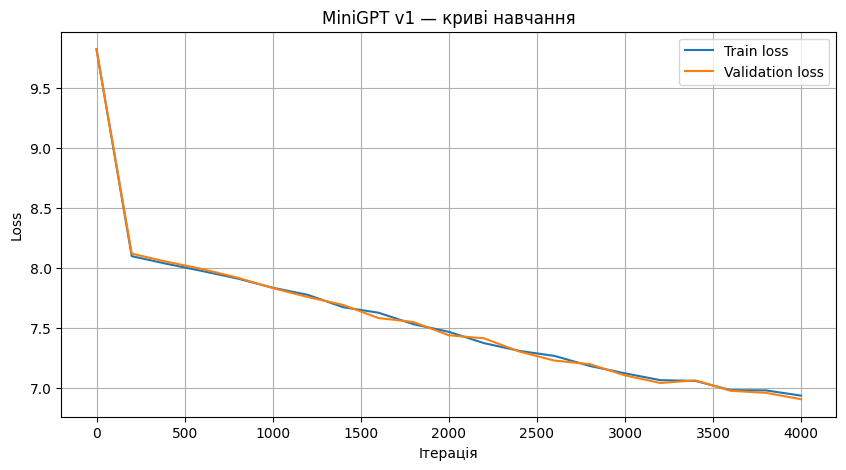

In [23]:
plt.figure(figsize=(10, 5))

plt.plot(checkpoint_iters, train_losses, label="Train loss")
plt.plot(checkpoint_iters, val_losses, label="Validation loss")

plt.xlabel("Ітерація")
plt.ylabel("Loss")
plt.title("MiniGPT v1 — криві навчання")
plt.legend()
plt.grid(True)
plt.show()

# Гіперпараметри другого варіанта MiniGPT v2

In [24]:
CONTEXT_LEN = 80
EMBED_DIM = 128
N_HEADS = 4
N_LAYERS = 3
DROPOUT = 0.1

BATCH_SIZE = 32
LEARNING_RATE = 3e-4
MAX_ITERS = 6000
EVAL_INTERVAL = 250
EVAL_ITERS = 20

# Перевіряємо сумісність розмірності ембедингів із кількістю голів
assert EMBED_DIM % N_HEADS == 0, \
    "EMBED_DIM має ділитися на N_HEADS"

HEAD_DIM = EMBED_DIM // N_HEADS
VOCAB_SIZE = gpt_tokenizer.get_vocab_size()

print("Параметри MiniGPT v2:")
print(f"Розмір словника: {VOCAB_SIZE}")
print(f"Довжина контексту: {CONTEXT_LEN}")
print(f"Розмір ембедингів: {EMBED_DIM}")
print(f"Кількість голів уваги: {N_HEADS}")
print(f"Кількість Transformer-блоків: {N_LAYERS}")
print(f"Розмір батчу: {BATCH_SIZE}")
print(f"Швидкість навчання: {LEARNING_RATE}")
print(f"Максимум ітерацій: {MAX_ITERS}")

Параметри MiniGPT v2:
Розмір словника: 16000
Довжина контексту: 80
Розмір ембедингів: 128
Кількість голів уваги: 4
Кількість Transformer-блоків: 3
Розмір батчу: 32
Швидкість навчання: 0.0003
Максимум ітерацій: 6000


# Створюємо другу версію мовної моделі з оновленими параметрами

In [25]:
model = MiniGPT(
    vocab_size=VOCAB_SIZE,
    embed_dim=EMBED_DIM,
    n_heads=N_HEADS,
    n_layers=N_LAYERS,
    context_len=CONTEXT_LEN,
    dropout=DROPOUT
).to(device)

# Обчислюємо кількість параметрів нової моделі
n_params = sum(
    param.numel()
    for param in model.parameters()
)

print(f"Кількість параметрів MiniGPT v2: {n_params:,}")
print(f"Обчислювальний пристрій: {device}")

Кількість параметрів MiniGPT v2: 4,716,160
Обчислювальний пристрій: cuda


# Навчання MiniGPT v2 та збереження найкращого чекпоінта

In [26]:
@torch.no_grad()
def estimate_loss():
    model.eval()
    loss_results = {}

    # Перевіряємо модель на обох вибірках
    for split in ("train", "val"):
        batch_losses = torch.zeros(EVAL_ITERS)

        for step in range(EVAL_ITERS):
            xb, yb = get_batch(split)
            _, loss = model(xb, yb)
            batch_losses[step] = loss.item()

        loss_results[split] = batch_losses.mean().item()

    model.train()
    return loss_results


# Налаштовуємо оптимізатор
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE
)

# Створюємо окремий журнал навчання для v2
writer = SummaryWriter(
    log_dir=os.path.join(RUNS_DIR, "minigpt_v2")
)

BEST_CKPT_PATH = os.path.join(
    ARTIFACT_DIR, "minigpt_v2.pt"
)

train_losses, val_losses, checkpoint_iters = [], [], []
best_val_loss = float("inf")
best_iter = None
start_time = time.time()

print("Розпочинаємо навчання MiniGPT v2...")

for it in range(MAX_ITERS):
    # Виконуємо один крок оптимізації
    xb, yb = get_batch("train")
    _, loss = model(xb, yb)

    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()

    # Періодично вимірюємо втрати
    if it % EVAL_INTERVAL == 0 or it == MAX_ITERS - 1:
        losses = estimate_loss()

        train_losses.append(losses["train"])
        val_losses.append(losses["val"])
        checkpoint_iters.append(it)

        writer.add_scalar("Loss/train", losses["train"], it)
        writer.add_scalar("Loss/val", losses["val"], it)

        elapsed_min = (time.time() - start_time) / 60

        print(
            f"Крок {it:4d} | "
            f"train_loss={losses['train']:.3f} | "
            f"val_loss={losses['val']:.3f} | "
            f"час={elapsed_min:.1f} хв"
        )

        # Зберігаємо параметри, якщо результат на валідації покращився
        if losses["val"] < best_val_loss:
            best_val_loss = losses["val"]
            best_iter = it

            torch.save({
                "model_state_dict": model.state_dict(),
                "vocab_size": VOCAB_SIZE,
                "context_len": CONTEXT_LEN,
                "embed_dim": EMBED_DIM,
                "n_heads": N_HEADS,
                "n_layers": N_LAYERS,
                "dropout": DROPOUT,
                "best_val_loss": best_val_loss,
                "best_iter": best_iter,
            }, BEST_CKPT_PATH)

writer.close()

print("\nНавчання MiniGPT v2 завершено.")
print(f"Найкращий крок: {best_iter}")
print(f"Мінімальний val_loss: {best_val_loss:.3f}")
print(f"Файл моделі: {BEST_CKPT_PATH}")

Розпочинаємо навчання MiniGPT v2...
Крок    0 | train_loss=9.830 | val_loss=9.830 | час=0.0 хв
Крок  250 | train_loss=8.061 | val_loss=8.062 | час=0.1 хв
Крок  500 | train_loss=7.923 | val_loss=7.926 | час=0.3 хв
Крок  750 | train_loss=7.767 | val_loss=7.768 | час=0.4 хв
Крок 1000 | train_loss=7.606 | val_loss=7.644 | час=0.5 хв
Крок 1250 | train_loss=7.493 | val_loss=7.478 | час=0.6 хв
Крок 1500 | train_loss=7.354 | val_loss=7.314 | час=0.8 хв
Крок 1750 | train_loss=7.227 | val_loss=7.225 | час=0.9 хв
Крок 2000 | train_loss=7.125 | val_loss=7.109 | час=1.0 хв
Крок 2250 | train_loss=7.006 | val_loss=7.002 | час=1.1 хв
Крок 2500 | train_loss=6.922 | val_loss=6.936 | час=1.3 хв
Крок 2750 | train_loss=6.837 | val_loss=6.843 | час=1.4 хв
Крок 3000 | train_loss=6.759 | val_loss=6.764 | час=1.5 хв
Крок 3250 | train_loss=6.671 | val_loss=6.681 | час=1.6 хв
Крок 3500 | train_loss=6.625 | val_loss=6.598 | час=1.8 хв
Крок 3750 | train_loss=6.517 | val_loss=6.514 | час=1.9 хв
Крок 4000 | train_lo

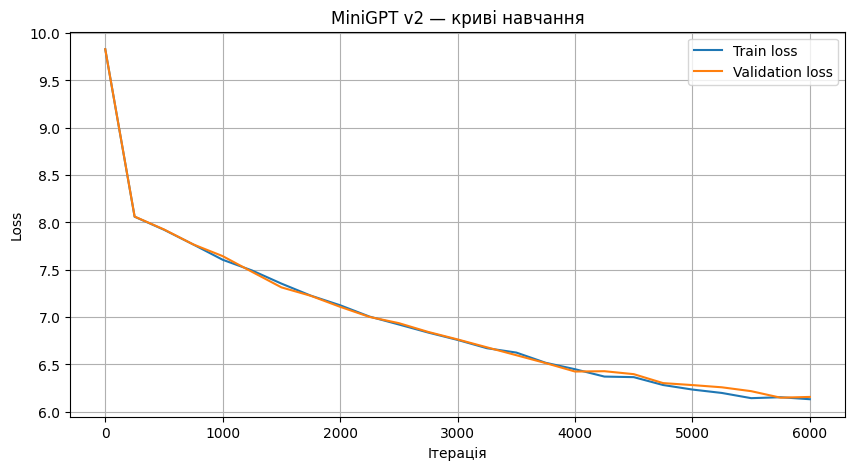

In [27]:
plt.figure(figsize=(10, 5))
plt.plot(checkpoint_iters, train_losses, label="Train loss")
plt.plot(checkpoint_iters, val_losses, label="Validation loss")

plt.xlabel("Ітерація")
plt.ylabel("Loss")
plt.title("MiniGPT v2 — криві навчання")
plt.legend()
plt.grid(True)
plt.show()

# Генерація тексту та зіставлення результатів двох моделей

In [28]:
import os
import torch

# Визначаємо розташування збережених моделей
V1_CKPT_PATH = os.path.join(ARTIFACT_DIR, "minigpt_v1.pt")
V2_CKPT_PATH = os.path.join(ARTIFACT_DIR, "minigpt_v2.pt")


def generate_text(
    checkpoint_path: str,
    prompt: str,
    max_new_tokens: int = 128,
    temperature: float = 0.8,
    top_k: int = 40,
) -> str:
    # Зчитуємо параметри та ваги вибраної моделі
    checkpoint = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=True
    )

    # Відтворюємо архітектуру відповідно до збережених налаштувань
    generator = MiniGPT(
        vocab_size=checkpoint["vocab_size"],
        embed_dim=checkpoint["embed_dim"],
        n_heads=checkpoint["n_heads"],
        n_layers=checkpoint["n_layers"],
        context_len=checkpoint["context_len"],
        dropout=checkpoint["dropout"],
    ).to(device)

    generator.load_state_dict(checkpoint["model_state_dict"])
    generator.eval()

    # Перетворюємо початковий текст на послідовність токенів
    input_ids = torch.tensor(
        [gpt_tokenizer.encode(prompt).ids],
        dtype=torch.long,
        device=device
    )

    # Отримуємо продовження заданого тексту
    with torch.no_grad():
        generated_ids = generator.generate(
            input_ids,
            max_new_tokens=max_new_tokens,
            temperature=temperature,
            top_k=top_k
        )

    # Повертаємо згенеровану послідовність у текстовому форматі
    return gpt_tokenizer.decode(generated_ids[0].tolist())


# Задаємо спільний початковий текст для обох варіантів
PROMPT = "Сьогодні у ночі сталася надзвичайна подія"

print("=== Результат MiniGPT v1 ===")
print(generate_text(V1_CKPT_PATH, PROMPT))

print("\n" + "-" * 60 + "\n")

print("=== Результат MiniGPT v2 ===")
print(generate_text(V2_CKPT_PATH, PROMPT))

=== Результат MiniGPT v1 ===
 Сьогодні у ночі сталася надзвичайна подія, а також ми не тільки і дуже, що в ході, він тому та не просто, в порядку, а потім це можуть є не тільки, що не можуть, які мають в процесі в яких все, що на б’я, не більше, він й в цій не були тому, щоб з цього його на те, в тому числі до речі і тому він і дуже в якій їх в межах, що вони, а також. Втримки, я він що не може бути він в якому. Я до неї на них для мене не в цілому для того є не тільки, на її та для дітей, що у

------------------------------------------------------------

=== Результат MiniGPT v2 ===
 Сьогодні у ночі сталася надзвичайна подія для отримання і ін. Ці. - це в якому можна вважати, що для цього року. На думку, хто ми знаємо в день, то це у ній, то не мали змогу не тільки. На жаль, як, що вони ще кілька років вже не ви зможете і я, але це не має бути він у випадку. Багато, як «побуто» (пані). До того, що, не потрібно був не буде ви можете ви маєте можливість робити? Я так, то з ким до самог

#Висновки

Порівняння двох варіантів MiniGPT показало, що модель v2 продемонструвала кращий результат за значенням функції втрат на валідаційній вибірці. Для v1 значення val_loss становило 6.889, тоді як для v2 воно знизилося до 6.137. Це свідчить про те, що другий варіант краще навчився прогнозувати наступні токени на даних, які не використовувалися безпосередньо для оновлення ваг моделі.

Під час генерації тексту обидві моделі змогли продовжити однаковий початковий запит, однак отримані результати залишаються недостатньо зв'язними та містять граматичні й змістові помилки. У тексті MiniGPT v1 спостерігаються фрагменти речень, які не утворюють послідовного повідомлення. MiniGPT v2 генерує більше конструкцій, схожих на офіційно-ділові та юридичні тексти, зокрема згадки про законодавство й нормативні документи, проте також допускає порушення логіки та структури речень.

---
## 4. Playground готових моделей

Тур по задачах через `pipeline()` — на основі [HF LLM Course, Chapter 1, §3](https://huggingface.co/learn/llm-course/en/chapter1/3).

_Зверніть увагу_: в межах попередніх завдань Ви могли завантажити памʼять "під завʼязку", тому для безпроблемного виконання наступних секцій вивільніть памʼять:

1. **Спершу збережіть усе потрібне на диск** — чекпоінти mini-GPT (`models/minigpt_v*.pt`), токенізатори, `results.csv`. Секції 4-6 від змінних секцій 1-3 не залежать, тож після цього їх можна сміливо видаляти.
2. **Видаліть великі обʼєкти** — моделі, оптимізатори, тензори `train_data`/`val_data`, корпус і `DataFrame`-и — і зберіть сміття:
   ```python
   import gc, torch

   del model, optimizer, train_data, val_data, corpus_text  # підставте свої імена змінних
   gc.collect()
   if torch.cuda.is_available():
       torch.cuda.empty_cache()
       print(f"GPU: зайнято {torch.cuda.memory_allocated() / 1e9:.2f} GB")
   ```
   Памʼять звільниться лише тоді, коли на обʼєкт не лишиться **жодного** посилання: зверніть увагу на копії в інших змінних, списках і словниках (наприклад, словник із кількома варіантами моделей).
3. **Перевірте, що памʼять справді звільнилась**: індикатор RAM/GPU вгорі праворуч.
4. **У самій секції 4 не тримайте всі pipeline-и одночасно**: кожен `pipeline(...)` завантажує окрему модель. Перевикористовуйте одну змінну (як `classifier` нижче) або робіть `del` + `gc.collect()` після кожної задачі.
5. **Стежте за диском**: моделі кешуються в `~/.cache/huggingface/hub`, і кілька моделей для summarization/translation легко займуть кілька ГБ. Переглянути й почистити кеш: `hf cache ls` / `hf cache rm <id моделі>`.

# Очищення пам'яті перед роботою з готовими моделями

In [29]:
import gc
import torch

# Видаляємо об'єкти, які могли залишитися після попередніх секцій
objects_to_delete = [
    "model",
    "optimizer",
    "train_data",
    "val_data",
    "data",
    "encoded_docs",
    "corpus_text",
    "poems_df",
    "dataset",
    "texts",
    "texts_list",
    "sample_texts",
    "word_list",
    "unique_words",
    "word_frequency",
    "comparison_df",
    "comparison_results",
    "bpe_tokenizer",
    "wordpiece_tokenizer",
    "unigram_tokenizer",
    "gpt_tokenizer",
    "base_tokenizer",
    "custom_qwen_tokenizer",
    "xb",
    "yb",
    "writer",
    "loss",
    "losses",
    "generated_ids",
    "output_ids",
    "prompt_ids",
    "generator",
    "checkpoint",
]

# Видаляємо лише ті змінні, які існують у поточному середовищі
for object_name in objects_to_delete:
    if object_name in globals():
        del globals()[object_name]

# Запускаємо збирач сміття Python
gc.collect()

# Очищаємо кеш CUDA, якщо доступна відеокарта
if torch.cuda.is_available():
    torch.cuda.empty_cache()
    print(f"GPU: зайнято {torch.cuda.memory_allocated() / 1e9:.2f} GB")
    print(f"GPU: зарезервовано {torch.cuda.memory_reserved() / 1e9:.2f} GB")
else:
    print("CUDA недоступна — очищено пам'ять Python.")

print("Очищення завершено.")


GPU: зайнято 0.22 GB
GPU: зарезервовано 0.33 GB
Очищення завершено.


### 4.0. Запустіть приклади виконання різних NLP задач

In [30]:
#!pip install "transformers[sentencepiece]==5.18.0"

In [31]:
# Sentiment analysis
from transformers import pipeline

classifier = pipeline("sentiment-analysis")
print(classifier("I've been waiting for a HuggingFace course my whole life."))
print(classifier(
    ["I've been waiting for a HuggingFace course my whole life.", "I hate this so much!"]
))

[transformers] No model was supplied, defaulted to distilbert/distilbert-base-uncased-finetuned-sst-2-english and revision 714eb0f.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

[{'label': 'POSITIVE', 'score': 0.9598046541213989}]
[{'label': 'POSITIVE', 'score': 0.9598046541213989}, {'label': 'NEGATIVE', 'score': 0.9994558691978455}]


In [32]:
# Zero-shot classification
from transformers import pipeline

classifier = pipeline("zero-shot-classification")
classifier(
    "This is a course about the Transformers library",
    candidate_labels=["education", "politics", "business"],
)

[transformers] No model was supplied, defaulted to facebook/bart-large-mnli and revision d7645e1.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/1.15k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.63GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/515 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

{'sequence': 'This is a course about the Transformers library',
 'labels': ['education', 'business', 'politics'],
 'scores': [0.844595193862915, 0.11197695881128311, 0.04342786595225334]}

In [33]:
# Text generation
from transformers import pipeline

generator = pipeline("text-generation")
print(generator("In this course, we will teach you how to"))

generator = pipeline("text-generation", model="distilgpt2")
print(generator(
    "In this course, we will teach you how to",
    max_length=30,
    num_return_sequences=2,
))

[transformers] No model was supplied, defaulted to HuggingFaceTB/SmolLM3-3B and revision a07cc9a.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/1.92k [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/26.9k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

...

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

[transformers] Passing `generation_config` together with generation-related arguments=({'num_return_sequences', 'max_length'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Both `max_new_tokens` (=256) and `max_length`(=30) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer GPT2Tokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


[{'generated_text': 'In this course, we will teach you how to get in touch with the people behind the project, so you can learn how to do it.\n\n\n\n\n\nThe following questions are required to get started in this course:\n1) How to get started with the project:\n2) How to get started with the project:\n3) How to get started with the project:\n4) How to get started with the project:\n5) How to get started with the project:\n6) How to get started with the project:\n7) How to get started with the project:\n8) How to get started with the project:\n9) How to get started with the project:\n10) How to get started with the project:\n11) How to get started with the project:\n12) How to get started with the project:\n13) How to get started with the project:\n14) How to get started with the project:\n16) How to get started with the project:\n17) How to get started with the project:\n18) How to get started with the project:\n19) How to get started with the project:\n20) How to get started with the

In [34]:
# Fill-mask
from transformers import pipeline

unmasker = pipeline("fill-mask")
unmasker("This course will teach you all about <mask> models.", top_k=2)

[transformers] No model was supplied, defaulted to distilbert/distilroberta-base and revision fb53ab8.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/480 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  331MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/106 [00:00<?, ?it/s]

...

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

[{'score': 0.19619743525981903,
  'token': 30412,
  'token_str': ' mathematical',
  'sequence': 'This course will teach you all about mathematical models.'},
 {'score': 0.04052695631980896,
  'token': 38163,
  'token_str': ' computational',
  'sequence': 'This course will teach you all about computational models.'}]

In [35]:
# Named entity recognition
from transformers import pipeline

ner = pipeline("ner", aggregation_strategy="simple")
ner("My name is Sylvain and I work at Hugging Face in Brooklyn.")

[transformers] No model was supplied, defaulted to dbmdz/bert-large-cased-finetuned-conll03-english and revision 4c53496.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/998 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.33GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

[transformers] BertForTokenClassification LOAD REPORT from: dbmdz/bert-large-cased-finetuned-conll03-english
Key                      | Status     |  | 
-------------------------+------------+--+-
bert.pooler.dense.bias   | UNEXPECTED |  | 
bert.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/60.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/213k [00:00<?, ?B/s]

[{'entity_group': 'PER',
  'score': np.float32(0.9981694),
  'word': 'Sylvain',
  'start': 11,
  'end': 18},
 {'entity_group': 'ORG',
  'score': np.float32(0.9796019),
  'word': 'Hugging Face',
  'start': 33,
  'end': 45},
 {'entity_group': 'LOC',
  'score': np.float32(0.9932106),
  'word': 'Brooklyn',
  'start': 49,
  'end': 57}]

In [36]:
# Question answering
from transformers import pipeline

question_answerer = pipeline("table-question-answering")
question_answerer(
    query="How many stars does the transformers repository have?",
    table={"Repository":["Transformers","Datasets","Tokenizers"],"Stars":["36542","4512","3934"],"Contributors":["651","77","34"],"Programming language":["Python","Python","Rust, Python and NodeJS"]},
)

[transformers] No model was supplied, defaulted to google/tapas-base-finetuned-wtq and revision e3dde19.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/1.66k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  443MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B /  443MB            

model.safetensors: downloading bytes:           |  0.00B            

vocab.txt:   0%|          | 0.00/262k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/154 [00:00<?, ?B/s]

{'answer': 'AVERAGE > 36542',
 'coordinates': [(0, 1)],
 'cells': ['36542'],
 'aggregator': 'AVERAGE'}

### 4.1. Свої приклади

Повторіть **усі 6 задач** вище (sentiment-analysis, zero-shot-classification, text-generation, fill-mask, NER, table-question-answering), але замість дефолтних англійських прикладів — придумайте й використайте **свої українськомовні приклади** для кожної задачі (якщо потрібно, підберіть відповідні моделі зі знанням української мови). Для виконання цього завдання постворюйте клітинки нижче.

#1 Sentiment analysis

In [37]:
from transformers import pipeline

# Завантажуємо мультимовну модель для класифікації тональності
sentiment_model = pipeline(
    "sentiment-analysis",
    model="Horizon-Labs/multilingual-sentiment-small"
)

# Власні українськомовні приклади за тематикою гри
souls_reviews = [
    "Битва з Душею Попелу неймовірна! Музика, атмосфера і кожна фаза бою просто захоплюють.",
    "Ненавиджу цей момент, коли бос перемагає мене десятий раз поспіль. Це вже не складність, а суцільне розчарування.",
    "Лотрік виглядає похмуро, а досліджувати його замки та руїни цікаво. Загалом гра залишає приємне враження."
]

# Визначаємо тональність кожного відгуку
results = sentiment_model(souls_reviews)

for review, result in zip(souls_reviews, results):
    print(f"Відгук: {review}")
    print(f"Мітка: {result['label']}")
    print(f"Впевненість: {result['score']:.3f}")
    print("-" * 60)

# Звільняємо пам'ять після завершення роботи
del sentiment_model


config.json:   0%|          | 0.00/2.08k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  563MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/138 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/46.4k [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 34.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/636 [00:00<?, ?B/s]

Відгук: Битва з Душею Попелу неймовірна! Музика, атмосфера і кожна фаза бою просто захоплюють.
Мітка: positive
Впевненість: 0.998
------------------------------------------------------------
Відгук: Ненавиджу цей момент, коли бос перемагає мене десятий раз поспіль. Це вже не складність, а суцільне розчарування.
Мітка: negative
Впевненість: 0.999
------------------------------------------------------------
Відгук: Лотрік виглядає похмуро, а досліджувати його замки та руїни цікаво. Загалом гра залишає приємне враження.
Мітка: positive
Впевненість: 0.995
------------------------------------------------------------


#2 Zero-shot classification

In [38]:
from transformers import pipeline

# Завантажуємо мультимовну модель для zero-shot класифікації
topic_classifier = pipeline(
    "zero-shot-classification",
    model="MoritzLaurer/mDeBERTa-v3-base-mnli-xnli"
)

# Описуємо ситуацію з гри Dark Souls III
game_description = (
    "Негорілий досліджує замок Лотрік, "
    "ухиляється від атак лицарів і шукає шлях до наступного боса."
)

# Визначаємо можливі категорії ігрового опису
game_categories = [
    "битви з босами",
    "дослідження локацій",
    "бойова система",
    "сюжет і персонажі",
    "ігрове спорядження"
]

# Визначаємо, які категорії найбільше відповідають тексту
classification = topic_classifier(
    game_description,
    candidate_labels=game_categories,
    multi_label=False
)

print("Опис ситуації:", game_description)
print("\nРезультати класифікації:")

for category, score in zip(
    classification["labels"],
    classification["scores"]
):
    print(f"{category}: {score:.3f}")

# Видаляємо модель після завершення експерименту
del topic_classifier


config.json:   0%|          | 0.00/1.07k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  558MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/1.26k [00:00<?, ?B/s]

...

tokenizer.json: reconstructing file:   0%|          |  0.00B / 16.3MB            

tokenizer.json: downloading bytes:           |  0.00B            

added_tokens.json:   0%|          | 0.00/23.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/286 [00:00<?, ?B/s]

Опис ситуації: Негорілий досліджує замок Лотрік, ухиляється від атак лицарів і шукає шлях до наступного боса.

Результати класифікації:
дослідження локацій: 0.446
битви з босами: 0.267
бойова система: 0.234
сюжет і персонажі: 0.043
ігрове спорядження: 0.011


#3 Text generation

In [39]:
from transformers import pipeline

# Завантажуємо модель для продовження українського тексту
text_generator = pipeline(
    "text-generation",
    model="malteos/gpt2-uk"
)

# Початок оповіді про подорож Негорілого
story_prompt = (
    "Коли Негорілий дістався до замку Лотрік, "
    "він побачив перед собою"
)

# Генеруємо два можливі продовження історії
generated_stories = text_generator(
    story_prompt,
    max_new_tokens=50,
    num_return_sequences=2,
    do_sample=True,
    temperature=0.8,
    top_k=40,
    pad_token_id=text_generator.tokenizer.eos_token_id
)

# Виводимо згенеровані варіанти
for number, story in enumerate(generated_stories, start=1):
    print(f"\nВаріант {number}:")
    print(story["generated_text"])

# Звільняємо пам'ять після виконання
del text_generator


config.json:   0%|          | 0.00/958 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  511MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

[transformers] GPT2LMHeadModel LOAD REPORT from: malteos/gpt2-uk
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
transformer.h.{0...11}.attn.masked_bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/344 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/3.84M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/96.0 [00:00<?, ?B/s]

[transformers] Passing `generation_config` together with generation-related arguments=({'num_return_sequences', 'do_sample', 'max_new_tokens', 'temperature', 'top_k', 'pad_token_id'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Both `max_new_tokens` (=50) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



Варіант 1:
Коли Негорілий дістався до замку Лотрік, він побачив перед собою величезну машину, в якій сидів і сидів, і, можливо, був мертвим, а той сидів на дивані біля своєї кімнати, де вижили, як тільки прокидався він і думав, що може бути, він не міг побачити, як

Варіант 2:
Коли Негорілий дістався до замку Лотрік, він побачив перед собою у повітрі сліди здуття. Коли Негорілий повернувся, то побачив на місці щось, подібне до того, що було раніше. Отак, Негорілий кинувся до річки, і його знову схопили ті, хто стояв біля нього. Нег


#4 Fill-mask

In [40]:
from transformers import pipeline

# Завантажуємо мультимовну модель для заповнення пропусків
mask_filler = pipeline(
    "fill-mask",
    model="FacebookAI/xlm-roberta-base"
)

# Речення про світ гри з пропущеним словом
masked_sentence = (
    "У Dark Souls III головний герой має перемогти "
    "<mask>, щоб відновити порядок у світі."
)

# Отримуємо п'ять найімовірніших варіантів
predictions = mask_filler(
    masked_sentence,
    top_k=5
)

print("Речення:", masked_sentence)
print("\nМожливі варіанти заповнення:")

for prediction in predictions:
    print(
        prediction["token_str"],
        "—",
        round(prediction["score"], 4)
    )

# Очищаємо змінну моделі після виконання
del mask_filler

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.12GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

[transformers] XLMRobertaForMaskedLM LOAD REPORT from: FacebookAI/xlm-roberta-base
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.bias   | UNEXPECTED |  | 
roberta.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

Речення: У Dark Souls III головний герой має перемогти <mask>, щоб відновити порядок у світі.

Можливі варіанти заповнення:
війну — 0.2126
всіх — 0.0564
владу — 0.0557
зло — 0.0406
США — 0.0249


#5 Named Entity Recognition

In [41]:
from transformers import pipeline

# Завантажуємо модель розпізнавання сутностей для української мови
entity_recognizer = pipeline(
    "ner",
    model="ukr-models/uk-ner",
    aggregation_strategy="simple"
)

# Описуємо події та персонажів ігрового світу
game_text = (
    "Негорілий вирушив до замку Лотрік, "
    "щоб перемогти Душу Попелу. "
    "Під час подорожі він відвідав поселення Нежиті."
)

# Визначаємо сутності, які розпізнала модель
recognized_entities = entity_recognizer(game_text)

for entity in recognized_entities:
    print(
        f"Текст: {entity['word']} | "
        f"Тип: {entity['entity_group']} | "
        f"Впевненість: {entity['score']:.3f}"
    )

# Видаляємо модель після завершення аналізу
del entity_recognizer

config.json:   0%|          | 0.00/1.01k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/457 [00:00<?, ?B/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B /  854kB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/2.37M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/238 [00:00<?, ?B/s]

Текст: Л | Тип: LOC | Впевненість: 1.000
Текст: от | Тип: LOC | Впевненість: 1.000
Текст: рік | Тип: LOC | Впевненість: 1.000
Текст: Душ | Тип: PER | Впевненість: 1.000
Текст: у Попелу | Тип: PER | Впевненість: 1.000
Текст: Не | Тип: LOC | Впевненість: 1.000
Текст: жит | Тип: LOC | Впевненість: 1.000
Текст: і | Тип: LOC | Впевненість: 1.000


#6 Table question answering

In [42]:
from transformers import pipeline

# Завантажуємо модель для запитань до таблиць
table_qa = pipeline(
    "table-question-answering",
    model="google/tapas-base-finetuned-wtq"
)

# Створюємо невелику таблицю з даними про босів
boss_table = {
    "Бос": [
        "Вордт з Холодної долини",
        "Понтифік Саліван",
        "Душа Попелу"
    ],
    "Кількість фаз": ["1", "2", "2"],
    "Складність": [
        "середня",
        "висока",
        "висока"
    ],
    "Локація": [
        "Висока стіна Лотріка",
        "Іритіл",
        "Піч Першого Полум'я"
    ]
}

# Ставимо запитання за вмістом таблиці
question = "Скільки фаз має Понтифік Саліван?"

answer = table_qa(
    query=question,
    table=boss_table
)

print("Запитання:", question)
print("Відповідь моделі:", answer)

# Видаляємо модель після завершення роботи
del table_qa

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

Запитання: Скільки фаз має Понтифік Саліван?
Відповідь моделі: {'answer': 'середня', 'coordinates': [(0, 2)], 'cells': ['середня'], 'aggregator': 'NONE'}


# Очищення RAM і пам'яті PyTorch після роботи з моделями


In [43]:
import gc
import ctypes
import torch

# 1. Видаляємо змінні моделей і результатів попередніх задач
objects_to_clear = [
    "classifier",
    "sentiment_model",
    "topic_classifier",
    "classification",
    "generator",
    "text_generator",
    "generated_stories",
    "result",
    "unmasker",
    "mask_filler",
    "predictions",
    "ner",
    "entity_recognizer",
    "recognized_entities",
    "question_answerer",
    "table_qa",
    "game_description",
    "game_categories",
    "souls_reviews",
    "game_text",
    "masked_sentence",
    "boss_table",
    "table",
    "answer",
    "optimizer",
    "model",
    "train_data",
    "val_data",
    "data",
    "encoded_docs",
    "corpus_text",
    "poems_df",
    "dataset",
    "texts",
    "sample_texts",
    "gpt_tokenizer",
    "base_tokenizer",
    "custom_qwen_tokenizer",
    "bpe_tokenizer",
    "wordpiece_tokenizer",
    "unigram_tokenizer",
    "xb",
    "yb",
]

for name in objects_to_clear:
    if name in globals():
        del globals()[name]

# 2. Збираємо об'єкти, які більше не використовуються
gc.collect()

# 3. Очищаємо кеш відеопам'яті
if torch.cuda.is_available():
    torch.cuda.empty_cache()
    torch.cuda.ipc_collect()

# 4. Просимо Linux повернути вільну пам'ять процесу системі
try:
    libc = ctypes.CDLL("libc.so.6")
    libc.malloc_trim(0)
except (OSError, AttributeError):
    pass

gc.collect()

# 5. Перевіряємо стан оперативної пам'яті
try:
    import psutil

    memory = psutil.virtual_memory()

    print(f"Загальна RAM: {memory.total / 1024**3:.2f} GB")
    print(f"Використано RAM: {memory.used / 1024**3:.2f} GB")
    print(f"Доступно RAM: {memory.available / 1024**3:.2f} GB")
    print(f"Завантаження RAM: {memory.percent}%")

except ImportError:
    print("Для статистики RAM виконай: %pip install psutil")

# 6. Перевіряємо використання GPU
if torch.cuda.is_available():
    print(
        f"Пам'ять GPU зайнята: "
        f"{torch.cuda.memory_allocated() / 1024**3:.2f} GB"
    )
    print(
        f"Пам'ять GPU зарезервована: "
        f"{torch.cuda.memory_reserved() / 1024**3:.2f} GB"
    )
else:
    print("CUDA GPU не використовується.")

print("\nОчищення завершено.")


Загальна RAM: 12.67 GB
Використано RAM: 5.23 GB
Доступно RAM: 7.12 GB
Завантаження RAM: 43.8%
Пам'ять GPU зайнята: 0.20 GB
Пам'ять GPU зарезервована: 0.31 GB

Очищення завершено.


---
## 5. Порівняння моделей

### 5.1. Оберіть задачу й метрику

Візьміть **одну** задачу зі списку нижче:

| Задача | Метрика | Що потрібно підготувати | Метрика в `evaluate` |
|---|---|---|---|
| sentiment-analysis | Accuracy / F1 | 15-20 своїх речень + правильна мітка (positive/negative) | [`accuracy`](https://huggingface.co/spaces/evaluate-metric/accuracy), [`f1`](https://huggingface.co/spaces/evaluate-metric/f1) |
| zero-shot-classification | Accuracy | те саме + фіксований список `candidate_labels` | [`accuracy`](https://huggingface.co/spaces/evaluate-metric/accuracy) |
| NER | F1 (entity-level) | кілька речень + список правильних сутностей (текст + тип) | [`seqeval`](https://huggingface.co/spaces/evaluate-metric/seqeval) |

Усі метрики рахуються через бібліотеку `evaluate` (той самий автор, що й `transformers`/`datasets`):
```python
import evaluate

metric = evaluate.load("rouge")  # або "accuracy", "f1", "seqeval", "squad", "sacrebleu"
metric.compute(predictions=[...], references=[...])
```
Формат `predictions`/`references` трохи відрізняється між метриками — дивіться приклад використання на сторінці кожної метрики (посилання в таблиці) або [HF Evaluate — Quick tour](https://huggingface.co/docs/evaluate/a_quick_tour).

### 5.2. Порівняйте моделі

На обраній задачі порівняйте щонайменше 2 різні моделі на однакових вхідних прикладах — не лише значення метрики, а й швидкість інференсу та розмір моделі (кількість параметрів).

### 5.3. Поекспериментуйте з налаштуваннями

Візьміть модель, що показала кращий результат, і поекспериментуйте з її налаштуваннями (temperature/top-p/top-k для генеративних задач, поріг впевненості для класифікаційних задач тощо) — щонайменше 3 зміни, по одній за раз, щоб зрозуміти, що саме впливає на метрику. Зведіть усі спроби (модель × налаштування → значення метрики) в невелику таблицю.

Коротко письмово: яка модель і яка комбінація налаштувань дала найкращий результат за обраною метрикою, і наскільки суттєво налаштування вплинули порівняно з вибором моделі?

# 5.1. Підготовка набору даних для аналізу тональності

In [44]:
texts = [
    "Dark Souls III має неймовірну атмосферу, я закохався в цей світ.",
    "Музика під час битви з Душею Попелу просто геніальна.",
    "Досліджувати Лотрік було дуже цікаво, кожна локація дивує.",
    "Бойова система чудова, а перемога над босом приносить задоволення.",
    "Мені подобається похмурий стиль і деталізація світу гри.",
    "Складні бої змушують вчитися, і це робить перемоги особливими.",
    "Персонажі та їхні історії додають грі загадковості.",
    "Зброя має різні стилі гри, тому цікаво експериментувати.",
    "Гра настільки захоплива, що я провів у ній цілий вечір.",
    "Фінальна битва залишила дуже сильне враження.",
    "Бос постійно перемагає мене, і це вже страшенно дратує.",
    "Керування здається незручним, особливо під час швидких боїв.",
    "Я загубився в локації й довго не міг знайти потрібний шлях.",
    "Деякі противники здаються несправедливо сильними.",
    "Після чергової поразки гра викликає лише розчарування.",
    "Камера іноді заважає стежити за рухами великого ворога.",
    "Мені не сподобалося, що важливі деталі сюжету так приховані.",
    "Повторювати один і той самий бій багато разів дуже втомлює.",
    "Деякі переходи між локаціями виглядають заплутаними.",
    "Гра цікава, але окремі механіки здаються надто незручними."
]

references = (
    ["positive"] * 10
    + ["negative"] * 10
)

assert len(texts) == len(references) == 20

print("Кількість прикладів:", len(texts))
print("Позитивних:", references.count("positive"))
print("Негативних:", references.count("negative"))

Кількість прикладів: 20
Позитивних: 10
Негативних: 10


#5.2. Порівняння двох моделей

In [45]:
%pip install -q transformers evaluate

In [46]:
import os
import gc
import time
import torch
import pandas as pd
import evaluate

from transformers import pipeline

# Каталог для результатів експерименту
MODEL_DIR = os.path.join(ARTIFACT_DIR)
os.makedirs(MODEL_DIR, exist_ok=True)

RESULTS_PATH = os.path.join("/content/drive/MyDrive/ai_systems/Lab3/", "results.csv")
accuracy_metric = evaluate.load("accuracy")

# Порівнюємо моделі на тих самих прикладах
models_to_test = [
    {
        "name": "multilingual_sentiment_small",
        "id": "Horizon-Labs/multilingual-sentiment-small"
    },
    {
        "name": "tabularisai_sentiment",
        "id": "tabularisai/multilingual-sentiment-analysis"
    }
]


def normalize_sentiment(label):
    """Зводимо різні назви класів до positive/negative."""
    label = label.lower().replace("_", " ")

    if "negative" in label:
        return "negative"
    if "positive" in label:
        return "positive"
    if "neutral" in label:
        return "neutral"

    return label


summary_results = []

for model_info in models_to_test:
    model_name = model_info["name"]
    model_id = model_info["id"]

    print(f"\nЗавантаження моделі: {model_id}")

    device_id = 0 if torch.cuda.is_available() else -1

    classifier = pipeline(
        "text-classification",
        model=model_id,
        device=device_id
    )

    model = classifier.model
    model.eval()

    params = sum(
        parameter.numel()
        for parameter in model.parameters()
    )

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    start = time.perf_counter()

    outputs = classifier(
        texts,
        batch_size=4,
        truncation=True
    )

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    elapsed = time.perf_counter() - start

    predictions = [
        normalize_sentiment(output["label"])
        for output in outputs
    ]
    scores = [float(output["score"]) for output in outputs]


    # Перетворюємо текстові класи на числові мітки
    label_to_id = {
        "negative": 0,
        "positive": 1
    }

    predictions_encoded = [
        label_to_id.get(label, -1)
        for label in predictions
    ]

    references_encoded = [
        label_to_id[label]
        for label in references
    ]

    # Обчислюємо Accuracy через evaluate
    metric_result = accuracy_metric.compute(
        predictions=predictions_encoded,
        references=references_encoded
    )
    accuracy = metric_result["accuracy"]

    result = {
        "Модель": model_name,
        "ID моделі": model_id,
        "Задача": "sentiment-analysis",
        "Accuracy": round(accuracy, 3),
        "Час, с": round(elapsed, 3),
        "Час на речення, с": round(elapsed / len(texts), 4),
        "Параметри, млн": round(params / 1_000_000, 2)
    }

    summary_results.append(result)

    print("Accuracy:", round(accuracy, 3))
    print("Час виконання:", round(elapsed, 3), "с")
    print("Кількість параметрів:", round(params / 1_000_000, 2), "млн")

    # Зберігаємо компактний артефакт без повних ваг моделі
    model_path = os.path.join(MODEL_DIR, f"{model_name}.pt")

    torch.save(
        {
            "model_name": model_name,
            "model_id": model_id,
            "task": "sentiment-analysis",
            "predictions": predictions,
            "scores": scores,
            "references": list(references),
            "texts": list(texts),
            "metrics": result
        },
        model_path
    )

    print(
        f"Артефакт: {model_path} "
        f"({os.path.getsize(model_path) / 1024:.1f} KB)"
    )

    # Записуємо передбачення кожного прикладу
    predictions_df = pd.DataFrame({
        "Тип тесту": ["sentiment-analysis"] * len(texts),
        "Модель": [model_name] * len(texts),
        "Речення": texts,
        "Правильна мітка": references,
        "Передбачення": predictions,
        "Оцінка": scores,
        "Accuracy": [round(accuracy, 3)] * len(texts),
        "Час, с": [round(elapsed, 3)] * len(texts),
        "Параметри, млн": [
            round(params / 1_000_000, 2)
        ] * len(texts)
    })

    predictions_df.to_csv(
        RESULTS_PATH,
        mode="a",
        header=not os.path.exists(RESULTS_PATH),
        index=False,
        encoding="utf-8-sig"
    )

    # Звільняємо ресурси перед завантаженням наступної моделі
    del classifier, model, outputs
    del predictions, scores, predictions_df
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

# Підсумкова таблиця для порівняння
summary_df = pd.DataFrame(summary_results)
display(summary_df)

print("\nРезультати CSV:", RESULTS_PATH)



Завантаження моделі: Horizon-Labs/multilingual-sentiment-small


Loading weights:   0%|          | 0/138 [00:00<?, ?it/s]

Accuracy: 0.9
Час виконання: 0.249 с
Кількість параметрів: 140.64 млн
Артефакт: /content/drive/MyDrive/ai_systems/Lab3/models/multilingual_sentiment_small.pt (4.3 KB)

Завантаження моделі: tabularisai/multilingual-sentiment-analysis


config.json:   0%|          | 0.00/851 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  541MB            

...

tokenizer.json:   0%|          | 0.00/2.92M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

Accuracy: 0.7
Час виконання: 0.067 с
Кількість параметрів: 135.33 млн
Артефакт: /content/drive/MyDrive/ai_systems/Lab3/models/tabularisai_sentiment.pt (4.2 KB)


,Модель,ID моделі,Задача,Accuracy,"Час, с","Час на речення, с","Параметри, млн"
0,multilingual_sentiment_small,Horizon-Labs/multilingual-sentiment-small,sentiment-analysis,0.9,0.249,0.0125,140.64
1,tabularisai_sentiment,tabularisai/multilingual-sentiment-analysis,sentiment-analysis,0.7,0.067,0.0034,135.33



Результати CSV: /content/drive/MyDrive/ai_systems/Lab3/results.csv


# Висновок

За результатами експерименту кращою для цієї задачі виявилася модель Horizon-Labs/multilingual-sentiment-small. Її точність становить 0,9 (90%), тоді як у tabularisai/multilingual-sentiment-analysis — 0,7 (70%). Отже, перша модель правильно класифікувала більшу кількість відгуків.

#Експерименти: зміна порогу впевненості

In [47]:
import os
import gc
import time
import torch
import pandas as pd
import evaluate

from transformers import pipeline

# Каталог для результатів експерименту
MODEL_DIR = os.path.join(ARTIFACT_DIR)
os.makedirs(MODEL_DIR, exist_ok=True)

RESULTS_PATH = os.path.join(
    "/content/drive/MyDrive/ai_systems/Lab3/",
    "results.csv"
)

accuracy_metric = evaluate.load("accuracy")

# Експериментуємо з порогом впевненості
thresholds = [0.00, 0.60, 0.75, 0.90]

model_name = "multilingual_sentiment_small"
model_id = "Horizon-Labs/multilingual-sentiment-small"

device_id = 0 if torch.cuda.is_available() else -1

print(f"Завантаження моделі: {model_id}")

classifier = pipeline(
    "text-classification",
    model=model_id,
    device=device_id
)

model = classifier.model
model.eval()

params = sum(
    parameter.numel()
    for parameter in model.parameters()
)

# Вимірюємо час класифікації
if torch.cuda.is_available():
    torch.cuda.synchronize()

start = time.perf_counter()

outputs = classifier(
    texts,
    batch_size=4,
    truncation=True
)

if torch.cuda.is_available():
    torch.cuda.synchronize()

elapsed = time.perf_counter() - start

predictions = [
    normalize_sentiment(output["label"])
    for output in outputs
]

scores = [
    float(output["score"])
    for output in outputs
]

label_to_id = {
    "negative": 0,
    "positive": 1
}

threshold_results = []

for threshold in thresholds:
    # Визначаємо, які прогнози проходять поріг
    accepted = [
        i for i, score in enumerate(scores)
        if score >= threshold
    ]

    accepted_predictions = [
        predictions[i] for i in accepted
    ]

    accepted_references = [
        references[i] for i in accepted
    ]

    # Accuracy обчислюємо лише для прийнятих прогнозів
    if accepted:
        predictions_encoded = [
            label_to_id.get(label, -1)
            for label in accepted_predictions
        ]

        references_encoded = [
            label_to_id[label]
            for label in accepted_references
        ]

        metric_result = accuracy_metric.compute(
            predictions=predictions_encoded,
            references=references_encoded
        )

        accuracy = metric_result["accuracy"]
    else:
        accuracy = 0.0

    coverage = len(accepted) / len(texts)

    result = {
        "Модель": model_name,
        "ID моделі": model_id,
        "Задача": "sentiment-analysis",
        "Поріг впевненості": threshold,
        "Accuracy": round(accuracy, 3),
        "Прийнято прогнозів": len(accepted),
        "Покриття, %": round(coverage * 100, 1),
        "Час, с": round(elapsed, 3),
        "Час на речення, с": round(elapsed / len(texts), 4),
        "Параметри, млн": round(params / 1_000_000, 2)
    }

    threshold_results.append(result)

    print(f"\nПоріг впевненості: {threshold}")
    print("Accuracy:", round(accuracy, 3))
    print("Прийнято прогнозів:", len(accepted), "з", len(texts))
    print("Покриття:", round(coverage * 100, 1), "%")

    # Зберігаємо окремий артефакт для кожного порога
    model_path = os.path.join(
        MODEL_DIR,
        f"{model_name}_{threshold}.pt"
    )

    torch.save(
        {
            "model_name": model_name,
            "model_id": model_id,
            "task": "sentiment-analysis",
            "threshold": threshold,
            "predictions": predictions,
            "scores": scores,
            "accepted_indices": accepted,
            "references": list(references),
            "texts": list(texts),
            "metrics": result
        },
        model_path
    )

    print(f"Артефакт збережено: {model_path}")

    # Записуємо результати для кожного речення
    predictions_df = pd.DataFrame({
        "Тип тесту": ["sentiment-analysis"] * len(texts),
        "Модель": [model_name] * len(texts),
        "ID моделі": [model_id] * len(texts),
        "Поріг впевненості": [threshold] * len(texts),
        "Речення": texts,
        "Правильна мітка": references,
        "Передбачення": predictions,
        "Оцінка": scores,
        "Прогноз прийнято": [
            i in accepted for i in range(len(texts))
        ],
        "Accuracy": [round(accuracy, 3)] * len(texts),
        "Покриття, %": [round(coverage * 100, 1)] * len(texts),
        "Час, с": [round(elapsed, 3)] * len(texts),
        "Параметри, млн": [
            round(params / 1_000_000, 2)
        ] * len(texts)
    })

    # Зберігаємо старі дані та додаємо нові рядки,
    # навіть якщо в нових експериментах є додаткові стовпці
    if os.path.exists(RESULTS_PATH):
        old_df = pd.read_csv(RESULTS_PATH)
        combined_df = pd.concat(
            [old_df, predictions_df],
            ignore_index=True,
            sort=False
        )
    else:
        combined_df = predictions_df

    combined_df.to_csv(
        RESULTS_PATH,
        index=False,
        encoding="utf-8-sig"
    )

    print("Результати додано до:", RESULTS_PATH)

# Підсумкова таблиця експериментів
threshold_df = pd.DataFrame(threshold_results)
display(threshold_df)

print("\nУсі результати CSV:", RESULTS_PATH)

# Звільняємо ресурси
del classifier, model, outputs
gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()



Завантаження моделі: Horizon-Labs/multilingual-sentiment-small


Loading weights:   0%|          | 0/138 [00:00<?, ?it/s]


Поріг впевненості: 0.0
Accuracy: 0.9
Прийнято прогнозів: 20 з 20
Покриття: 100.0 %
Артефакт збережено: /content/drive/MyDrive/ai_systems/Lab3/models/multilingual_sentiment_small_0.0.pt
Результати додано до: /content/drive/MyDrive/ai_systems/Lab3/results.csv

Поріг впевненості: 0.6
Accuracy: 0.889
Прийнято прогнозів: 18 з 20
Покриття: 90.0 %
Артефакт збережено: /content/drive/MyDrive/ai_systems/Lab3/models/multilingual_sentiment_small_0.6.pt
Результати додано до: /content/drive/MyDrive/ai_systems/Lab3/results.csv

Поріг впевненості: 0.75
Accuracy: 0.938
Прийнято прогнозів: 16 з 20
Покриття: 80.0 %
Артефакт збережено: /content/drive/MyDrive/ai_systems/Lab3/models/multilingual_sentiment_small_0.75.pt
Результати додано до: /content/drive/MyDrive/ai_systems/Lab3/results.csv

Поріг впевненості: 0.9
Accuracy: 0.9
Прийнято прогнозів: 10 з 20
Покриття: 50.0 %
Артефакт збережено: /content/drive/MyDrive/ai_systems/Lab3/models/multilingual_sentiment_small_0.9.pt
Результати додано до: /content/dri

,Модель,ID моделі,Задача,Поріг впевненості,Accuracy,Прийнято прогнозів,"Покриття, %","Час, с","Час на речення, с","Параметри, млн"
0,multilingual_sentiment_small,Horizon-Labs/multilingual-sentiment-small,sentiment-analysis,0.00,0.900,20,100.0,0.219,0.0109,140.64
1,multilingual_sentiment_small,Horizon-Labs/multilingual-sentiment-small,sentiment-analysis,0.60,0.889,18,90.0,0.219,0.0109,140.64
2,multilingual_sentiment_small,Horizon-Labs/multilingual-sentiment-small,sentiment-analysis,0.75,0.938,16,80.0,0.219,0.0109,140.64
3,multilingual_sentiment_small,Horizon-Labs/multilingual-sentiment-small,sentiment-analysis,0.90,0.900,10,50.0,0.219,0.0109,140.64



Усі результати CSV: /content/drive/MyDrive/ai_systems/Lab3/results.csv


#Висновок

Найкращий результат показала модель Horizon-Labs/multilingual-sentiment-small із порогом впевненості 0,75 — Accuracy становила 93,8% при покритті 80%. Порівняно з базовим результатом (90%), точність зросла на 3,8 відсоткового пункта. Отже, налаштування порога позитивно вплинуло на точність, але збільшення порога не завжди покращує результат.

---
## 6. Творчий застосунок

Побудуйте невеликий Gradio-застосунок на основі будь-якої готової моделі з розділів 4-5 — тема й формат повністю на ваш вибір, заохочується творчість і щось не зовсім очевидне (не просто "ще один чат-бот"). Це може бути й генеративна LLM через `transformers` (`AutoModelForCausalLM`/`AutoTokenizer` або `pipeline("text-generation", ...)`, той самий патерн, що й у демо 4.1-4.2 на Qwen) — `text-generation` уже входить до обов'язкових 8 задач розділу 4, тож це не вихід за межі завдання. Головне — щоб застосунок реально запускався і демонстрував конкретну, зрозумілу користувацьку цінність.

In [48]:
%pip install -q gradio transformers torch

import gradio as gr
import torch
from transformers import pipeline

# Завантажуємо модель із попереднього експерименту
MODEL_ID = "Horizon-Labs/multilingual-sentiment-small"

device_id = 0 if torch.cuda.is_available() else -1

sentiment_model = pipeline(
    "text-classification",
    model=MODEL_ID,
    device=device_id
)


def analyze_review(text):
    if not text or not text.strip():
        return "—", "—", "Спочатку напиши відгук, мандрівнику."

    # Аналізуємо тональність відгуку
    result = sentiment_model(text.strip(), truncation=True)[0]

    label = result["label"].lower().replace("_", " ")
    confidence = float(result["score"])

    if "positive" in label:
        sentiment = "Позитивна"
        advice = (
            "🔥 Полум'я ще горить! Твоя подорож Лотріком "
            "залишила добрі враження. Продовжуй досліджувати "
            "цей похмурий світ!"
        )
    elif "negative" in label:
        sentiment = "Негативна"
        advice = (
            "🗡️ Навіть найсильніші Попелясті зазнають невдач. "
            "Спробуй іншу тактику, досліди локацію або "
            "повернися до складного ворога пізніше."
        )
    else:
        sentiment = "Невизначена"
        advice = (
            "🌫️ Туман приховує твої справжні враження. "
            "Спробуй описати їх докладніше."
        )

    confidence_text = f"{confidence * 100:.1f}%"

    return sentiment, confidence_text, advice


# Приклади для швидкого тестування
examples = [
    ["Битва з Душею Попелу неймовірна, а музика просто геніальна!"],
    ["Цей бос постійно перемагає мене. Бій уже дратує."],
    ["Лотрік похмурий, але досліджувати його дуже цікаво."]
]

# Створюємо інтерфейс
with gr.Blocks(
    theme=gr.themes.Soft(),
    title="Вісник Лотріка"
) as app:

    gr.Markdown(
        """
        # 🔥 Вісник Лотріка
        ### Хроніки Попелястого

        *Мандрівнику, розкажи про свою подорож.
        Вісник проаналізує твої враження від Dark Souls III.*
        """
    )

    review_input = gr.Textbox(
        label="Твій відгук",
        placeholder="Напиши про боса, локацію, музику або бойову систему...",
        lines=4
    )

    analyze_button = gr.Button(
        "⚔️ Проаналізувати відгук",
        variant="primary"
    )

    gr.Examples(
        examples=examples,
        inputs=review_input,
        label="Приклади відгуків"
    )

    gr.Markdown("### 📜 Результати аналізу")

    with gr.Row():
        sentiment_output = gr.Textbox(
            label="Тональність",
            interactive=False
        )
        confidence_output = gr.Textbox(
            label="Впевненість моделі",
            interactive=False
        )

    advice_output = gr.Textbox(
        label="Послання Вісника",
        lines=3,
        interactive=False
    )

    analyze_button.click(
        fn=analyze_review,
        inputs=review_input,
        outputs=[
            sentiment_output,
            confidence_output,
            advice_output
        ]
    )

    review_input.submit(
        fn=analyze_review,
        inputs=review_input,
        outputs=[
            sentiment_output,
            confidence_output,
            advice_output
        ]
    )

app.launch(share=True)

Loading weights:   0%|          | 0/138 [00:00<?, ?it/s]

/tmp/ipykernel_3673/3328158896.py:63: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://787ea2e6efcf0be693.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


---
### Як здавати лабу

У [форму](https://forms.gle/Z1gxmsDs656jqsDGA) здати посилання на **публічний** репозиторій, який містить:

1. **Демо-ноутбук з усіма виконаними пунктами**. Має запускатися зверху до низу (Run All) в будь-якому середовищі без помилок.
2. **Цей ноутбук з усіма виконаними пунктами**. Має запускатися зверху до низу (Run All) в будь-якому середовищі без помилок.
3. **Файли всіх натренованих варіантів mini-GPT** (3.2) — кожен окремим `.pt` файлом.
4. **Логи TensorBoard** — папка `runs/` з усіма прогонами (і mini-GPT, і, за бажання, логи порівняння в розділі 5).
5. **Таблицю результатів** — `results.csv` з порівнянням варіантів mini-GPT (val_loss) і моделей з розділу 5.
6. Структура файлів на репозиторії, **точно дотримуйтесь, інакше не зарахується лаба**:
```
/lab3/transformers_demo.ipynb
/lab3/transformers_task.ipynb
/lab3/models/minigpt_v1.pt
/lab3/models/minigpt_v2.pt
/lab3/models/...        (усі інші варіанти з 3.2)
/lab3/runs/*
/lab3/results.csv
```